In [1]:
import zipfile
with zipfile.ZipFile('X_train_9po2I7U.zip', 'r') as z:
    print(z.namelist())  # voir ce qu'il y a dedans
    z.extractall("data/")  # extraire

['X_train/', 'X_train/clinical_train.csv', 'X_train/molecular_train.csv']


In [2]:

import pandas as pd
df_cli=pd.read_csv("data/X_train/clinical_train.csv")
df_mol=pd.read_csv("data/X_train/molecular_train.csv")
df_lab=pd.read_csv("target_train.csv")
                   

In [3]:
from skrub import TableReport
from IPython.display import display

for i in [df_cli, df_mol, df_lab]:
    report = TableReport(i)
    display(report)

,,,,,,,,,


,,,,,,,,,,,


<TableReport: use .open() to display>

# 🧬 Comprendre la Leucémie Myéloïde Aiguë (LMA) : contexte biologique et rôle des variables

Avant de nettoyer les données et d'entraîner nos modèles de survie, il est essentiel de comprendre **ce que représente réellement chaque variable**. En santé, et particulièrement en oncologie, ignorer la biologie sous-jacente conduit à des modèles biaisés, qui passent à côté des vrais signaux de survie ou qui interprètent mal une relation statistique.

Cette section explique la maladie en langage clair, puis détaille le rôle biologique et pronostique de chaque covariable de nos jeux de données.

---

## 1. La maladie : quand l'usine à sang tombe en panne

Dans un corps en bonne santé, la **moelle osseuse** (le tissu spongieux situé à l'intérieur de nos os) fonctionne comme une usine. Elle contient des cellules souches qui se divisent puis se transforment progressivement pour donner naissance aux trois grandes familles de cellules sanguines :

- les **globules rouges**, qui transportent l'oxygène dans tout le corps ;
- les **plaquettes**, qui permettent au sang de coaguler et de boucher les plaies ;
- les **globules blancs**, qui constituent notre système de défense contre les infections.

La **Leucémie Myéloïde Aiguë (LMA)** apparaît lorsqu'une de ces cellules souches subit une mutation génétique accidentelle — une sorte de « bug » dans son code source. Ce bug provoque deux catastrophes en même temps :

1. **Un blocage de la maturation.** La cellule cesse de se différencier normalement et reste bloquée à un stade immature, appelé **blaste**. Un blaste est biologiquement inutile : il ne transporte pas d'oxygène, ne coagule pas le sang, et ne combat pas les infections.
2. **Une prolifération incontrôlée.** La cellule perd la capacité de mourir naturellement (ce mécanisme de mort programmée s'appelle l'**apoptose**) et se met à se cloner à une vitesse anormale.

**Conséquence directe : l'insuffisance médullaire.** Les blastes envahissent progressivement la moelle osseuse et prennent toute la place. Il n'y a plus assez d'espace pour fabriquer du sang normal. Le patient se retrouve donc en danger vital — non pas à cause d'une tumeur solide qui comprime un organe, mais parce que son sang ne remplit plus ses fonctions vitales : il ne transporte plus assez d'oxygène, ne coagule plus, et ne le protège plus des infections.

C'est cette logique en deux temps qui va guider toute notre lecture des données :
- **à court terme**, le patient survivra-t-il à cet effondrement sanguin initial ?
- **à long terme**, si le traitement nettoie la moelle, la maladie va-t-elle revenir ?

---

## 2. Le bilan sanguin à l'admission : mesurer l'urgence

### `BM_BLAST` — pourcentage de blastes dans la moelle osseuse
C'est la mesure directe de l'envahissement de la moelle par les cellules malades. Le diagnostic de LMA est posé lorsque ce taux dépasse 20 %. Certains patients arrivent avec 90 % de blastes : leur moelle est presque entièrement remplacée par la maladie. Plus ce chiffre est élevé, plus il faudra de traitement pour « nettoyer » la moelle.

### `ANC` — nombre absolu de neutrophiles
Les neutrophiles sont les globules blancs de première ligne, chargés de détruire les bactéries. Un `ANC` proche de zéro signifie que le patient n'a quasiment plus de défense immunitaire et risque à tout moment une infection généralisée mortelle (choc septique). C'est un facteur très fortement associé au **décès précoce** — mais son influence a tendance à s'atténuer avec le temps chez les patients qui survivent aux premières semaines (on parle d'effet **non-proportionnel** dans le temps, un point important pour le choix du modèle de survie).

### `HB` — hémoglobine
L'hémoglobine est la molécule qui, dans les globules rouges, transporte l'oxygène. Une `HB` basse indique une anémie sévère : le patient manque d'oxygène et son cœur doit compenser en travaillant plus fort, ce qui l'épuise.

### `PLT` — plaquettes
Les plaquettes assurent la coagulation du sang. Un taux très bas expose le patient à un risque d'hémorragie spontanée, notamment cérébrale, qui peut être fatale.

### `WBC` — globules blancs totaux et `MONOCYTES`
Cette variable compte l'ensemble des globules blancs circulant dans le sang (les cellules saines + les blastes qui ont débordé de la moelle vers la circulation). Sa relation avec le risque de décès a une forme particulière, dite **« en U »** :
- un `WBC` très bas traduit un déficit immunitaire (risque d'infection) ;
- un `WBC` très élevé (par exemple au-delà de 100 G/L) signifie que le sang contient une quantité massive de blastes, au point de devenir épais comme du sirop. Ces cellules finissent par boucher les petits vaisseaux du cerveau ou des poumons — une urgence vitale appelée **leucostase**.

Autrement dit, le danger est présent aux deux extrêmes de cette variable, pas seulement à une extrémité. Un modèle qui suppose une relation simplement croissante ou décroissante avec cette variable passera à côté de ce phénomène.

### `CENTER` — centre de traitement
Cette variable n'a pas de sens biologique en soi, mais elle capte un effet indirect important : certains centres hospitaliers (souvent des CHU spécialisés) reçoivent préférentiellement les cas les plus graves, ou au contraire ont accès à des traitements expérimentaux. Cela peut créer un **biais de recrutement** qu'il faudra garder à l'esprit lors de la modélisation.

---

## 3. Le caryotype (`CYTOGENETICS`) : la carte d'identité chromosomique de la tumeur

Le cancer est avant tout une maladie de l'ADN. Pour évaluer les chances de survie à long terme, les médecins examinent les **chromosomes** (les grands « rouleaux » qui contiennent notre ADN) des cellules leucémiques. C'est historiquement l'un des facteurs pronostiques les plus puissants en LMA.

La colonne `CYTOGENETICS` contient une description textuelle codée (nomenclature ISCN) de l'état de ces chromosomes. On distingue globalement trois situations :

- **Anomalies favorables (translocations).** Parfois, deux chromosomes échangent un morceau. Étonnamment, c'est souvent une bonne nouvelle : cette anomalie devient une cible très spécifique, que certaines chimiothérapies savent particulièrement bien attaquer.
- **Anomalies défavorables (délétions, caryotype complexe).** Lorsqu'un chromosome entier manque (par exemple la perte du chromosome 7, notée `-7`) ou qu'un gros morceau est supprimé (`del`), la cellule perd des gènes qui jouaient normalement un rôle protecteur. Quand on observe trois anomalies ou plus (« caryotype complexe »), l'ADN de la tumeur est profondément désorganisé : la cellule devient chaotique et développe facilement des résistances aux traitements. Le pronostic est alors très défavorable.
- **Caryotype normal.** Les chromosomes paraissent visuellement intacts. Cela ne signifie pas que le patient est hors de danger : la maladie peut se cacher à une échelle plus fine, invisible au microscope — celle des mutations ponctuelles.

---

## 4. Les mutations génétiques (`X_train_genetic`) : la biologie à l'échelle moléculaire

Si le caryotype est le plan général de la ville, les données génétiques décrivent l'état de chaque serrure de chaque maison : les erreurs précises dans le texte de l'ADN.

### `GENE` — quel mécanisme est touché ?
- **FLT3** fonctionne normalement comme une pédale d'accélérateur pour la division cellulaire. Muté, il reste bloqué en position « accélération » : la maladie devient plus agressive et a tendance à rechuter après traitement.
- **TP53** est surnommé le « gardien du génome » : son rôle est de forcer une cellule endommagée à s'autodétruire. C'est justement ce mécanisme que la chimiothérapie exploite pour tuer les cellules cancéreuses. Si `TP53` est muté, les cellules refusent de mourir même endommagées : la chimiothérapie perd une grande partie de son efficacité. C'est l'une des altérations de plus mauvais pronostic.
- **NPM1** est une mutation fréquente qui, lorsqu'elle est isolée (sans mutation FLT3 associée), est plutôt associée à un bon pronostic.

### `EFFECT` / `PROTEIN_CHANGE` — la gravité de l'erreur génétique
Toutes les mutations d'un même gène ne se valent pas :
- une mutation *missense* (« faux-sens ») modifie légèrement la forme de la protéine, qui peut encore fonctionner partiellement ;
- une mutation *nonsense* ou *frameshift* casse complètement la lecture du gène, détruisant la protéine.

### `VAF` (Variant Allele Frequency) — la taille de l'armée mutée
Le VAF indique quelle proportion des cellules tumorales porte une mutation donnée. Il agit comme un multiplicateur de dangerosité :
- une mutation TP53 présente chez 80 % des cellules tumorales indique que la quasi-totalité de la tumeur est résistante au traitement — risque maximal ;
- la même mutation présente chez seulement 2 % des cellules ne concerne qu'un sous-groupe minoritaire, avec un impact beaucoup plus limité.

---

## 5. Synthèse : une course de survie en deux temps

| Horizon de risque | Mécanisme biologique | Variables concernées |
|---|---|---|
| **Court terme** | Effondrement du sang normal (infection, hémorragie, anémie) | `ANC`, `WBC`, `PLT`, `HB`, `BM_BLAST` |
| **Long terme** | Résistance et rechute liées à la génétique de la tumeur | `CYTOGENETICS`, `GENE`, `VAF`, `EFFECT` |

Cette double lecture — un risque immédiat lié à l'état sanguin, et un risque différé lié à la génétique tumorale — doit guider nos choix de modélisation : transformations non linéaires pour les variables en « U » comme `WBC`, extraction de features structurées à partir du texte de `CYTOGENETICS`, et prise en compte du VAF comme pondération de la sévérité des mutations.

array([[<Axes: title={'center': 'BM_BLAST'}>,
        <Axes: title={'center': 'WBC'}>],
       [<Axes: title={'center': 'ANC'}>,
        <Axes: title={'center': 'MONOCYTES'}>],
       [<Axes: title={'center': 'HB'}>, <Axes: title={'center': 'PLT'}>]],
      dtype=object)

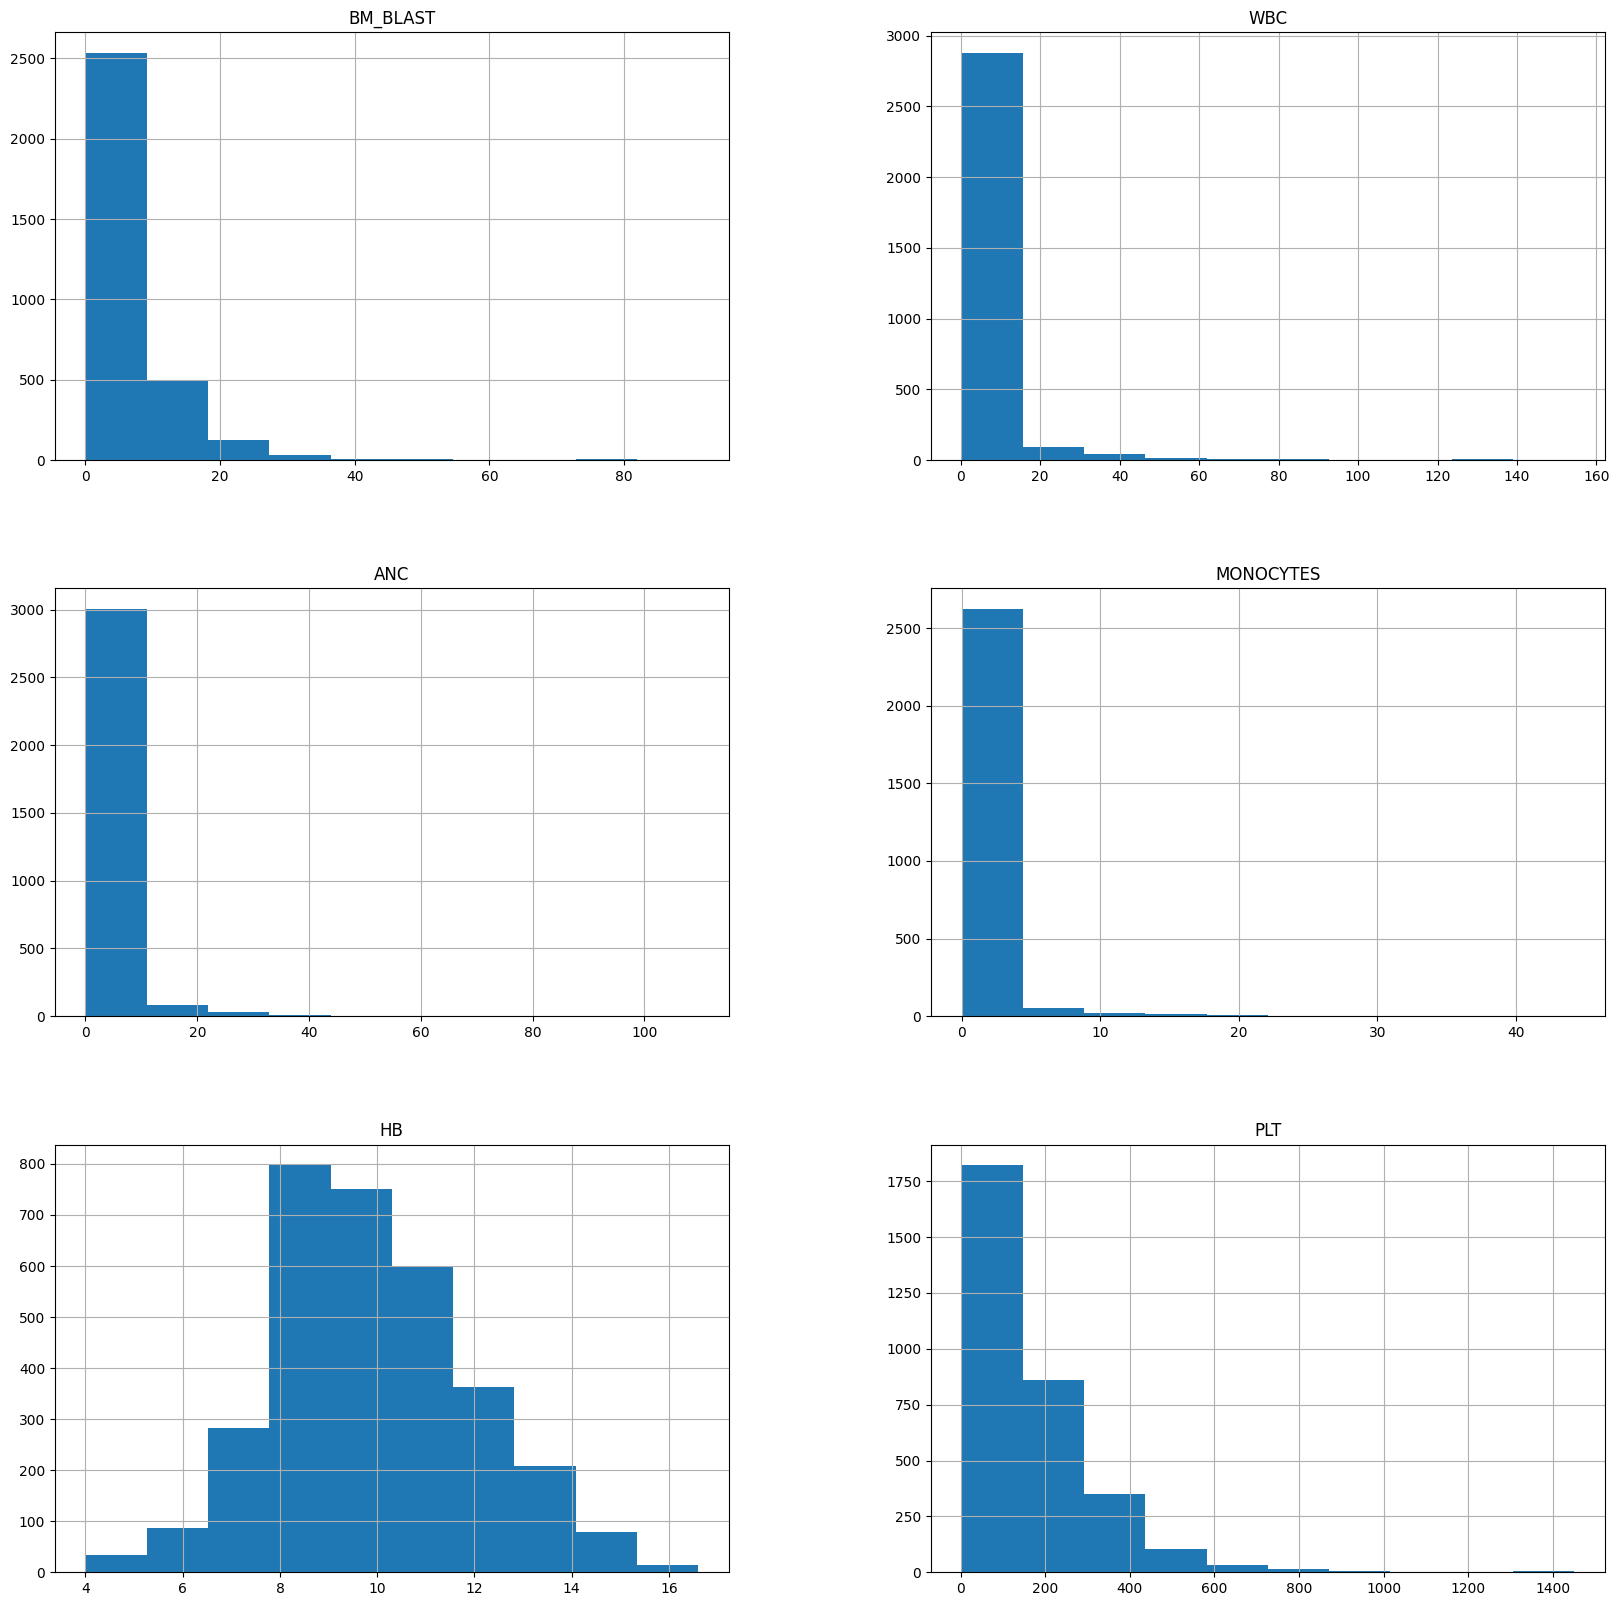

In [4]:
#visualisation-histogrammes

import matplotlib.pyplot as plt
df_cli.hist(figsize=(20, 20))





array([[<Axes: title={'center': 'START'}>,
        <Axes: title={'center': 'END'}>],
       [<Axes: title={'center': 'VAF'}>,
        <Axes: title={'center': 'DEPTH'}>]], dtype=object)

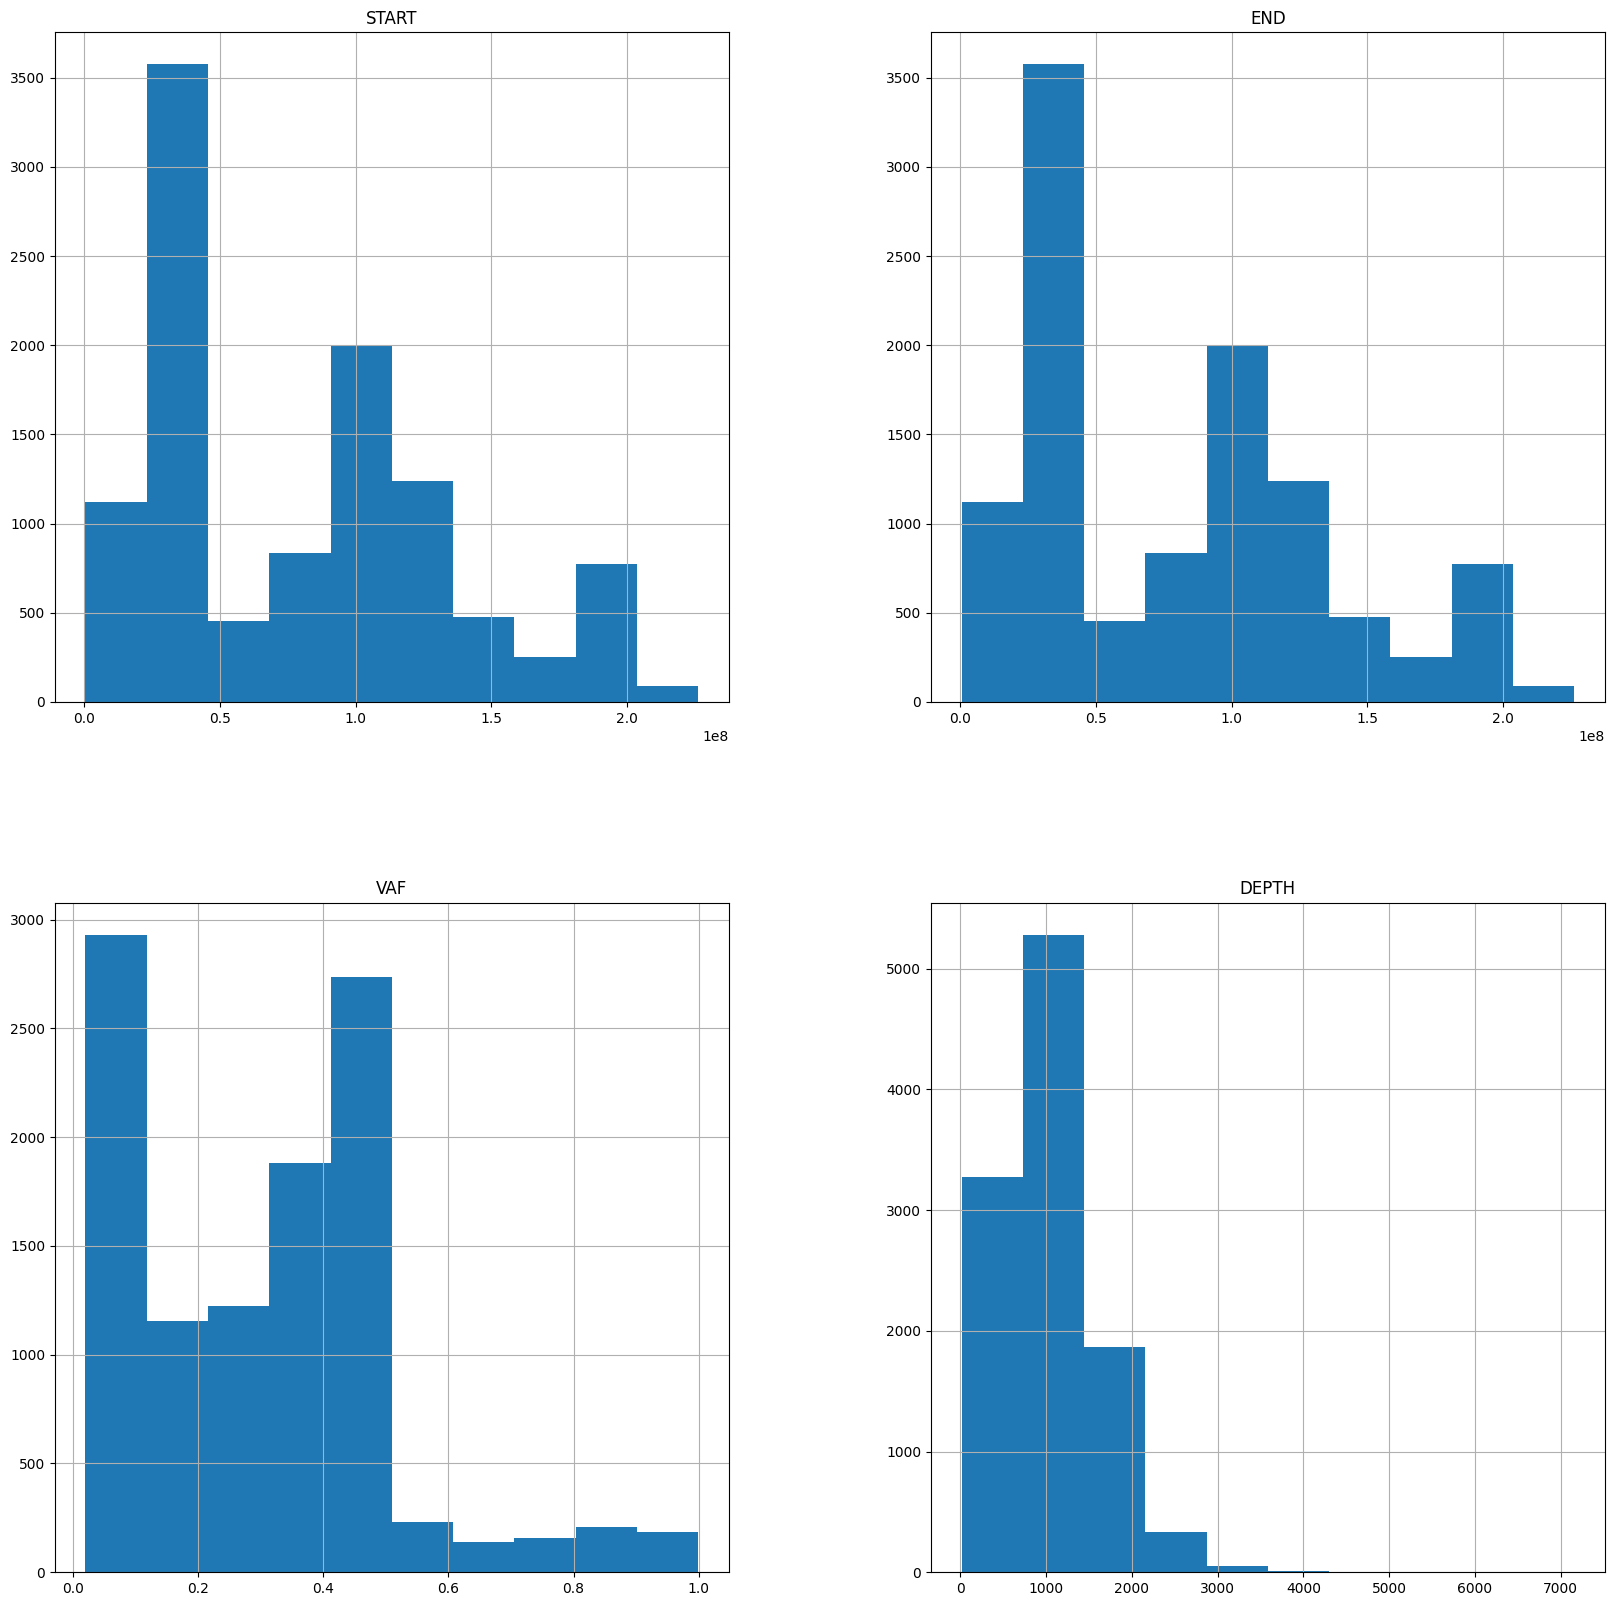

In [5]:
df_mol.hist(figsize=(20, 20))

## Feuille de route méthodologique

1. **Analyse non-paramétrique globale et par sous-groupes** : estimateurs de Kaplan–Meier $\hat S_{\mathrm{KM}}(t)$, de Nelson–Aalen $\hat H_{\mathrm{NA}}(t)$ et test du Log-Rank multivarié.
2. **Ingénierie des variables moléculaires** : agrégation du multiensemble de mutations somatiques $\mathcal M_i$ par patient (gènes mutés, charge clonale VAF, effets fonctionnels).
3. **Modèle de référence (Benchmark)** : modèle de Cox à risques proportionnels pénalisé et **test des résidus de Schoenfeld** pour éprouver l'hypothèse de proportionnalité des risques.
4. **Méthodes d'arbres et d'ensembles** : Arbre de survie CART (critère du Log-Rank), *Random Survival Forest* (RSF) et *Gradient Boosting* de Cox.
5. **Réseaux de neurones profonds** : **DeepSurv** (risques proportionnels non-linéaires) et **PC-Hazard** (risque constant par morceaux sans hypothèse de proportionnalité, sur grille équidistante grossière $L=5$ vs grille aux quantiles de Kaplan–Meier $L=20$).
6. **Évaluation externe et Calibration** : C-index de Harrell, C-index IPCW de Uno, *Integrated Brier Score* (IBS) et courbes de calibration à horizon fixé $t^\star$.

In [6]:
df_lab.columns


Index(['ID', 'OS_YEARS', 'OS_STATUS'], dtype='object')

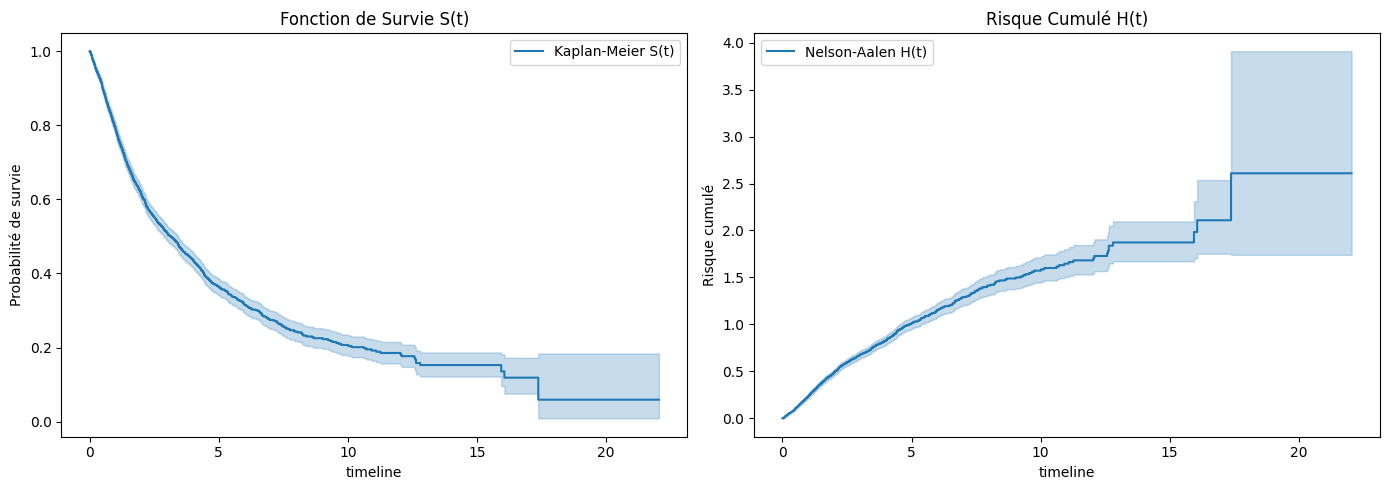

(<lifelines.KaplanMeierFitter:"Kaplan-Meier S(t)", fitted with 3173 total observations, 1573 right-censored observations>,
 <lifelines.NelsonAalenFitter:"Nelson-Aalen H(t)", fitted with 3173 total observations, 1573 right-censored observations>)

In [7]:
#pipeline kaplan meier et nelson allen ( dropna puis fit)
from lifelines import KaplanMeierFitter, NelsonAalenFitter

kmf = KaplanMeierFitter()
naf = NelsonAalenFitter()

def kmna(df_lab):
    df_clean = df_lab.dropna().copy()
    

    kmf.fit(durations=df_clean['OS_YEARS'], 
            event_observed=df_clean['OS_STATUS'], 
            label='Kaplan-Meier S(t)')

    naf.fit(durations=df_clean['OS_YEARS'], 
            event_observed=df_clean['OS_STATUS'], 
            label='Nelson-Aalen H(t)')

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    
    kmf.plot_survival_function(ax=axes[0])
    axes[0].set_title('Fonction de Survie S(t)')
    axes[0].set_ylabel('Probabilité de survie')
    
    naf.plot_cumulative_hazard(ax=axes[1])
    axes[1].set_title('Risque Cumulé H(t)')
    axes[1].set_ylabel('Risque cumulé')
    
    plt.tight_layout()
    plt.show()
    
    return kmf, naf

kmna(df_lab)




## Analyse de l'effet du centre hospitalier (`CENTER`) sur la survie

<Axes: title={'center': 'Distribution des centres'}, xlabel='CENTER'>

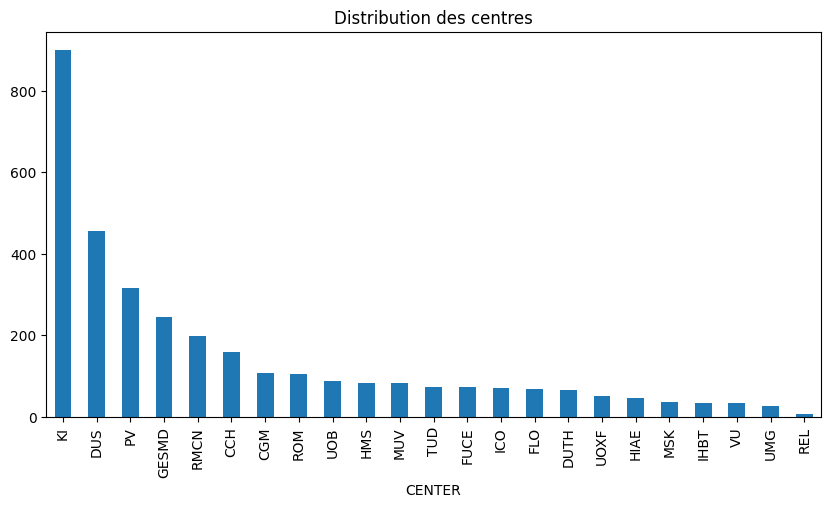

In [8]:
df_cli['CENTER'].value_counts().plot(kind='bar', figsize=(10, 5), title='Distribution des centres')

In [9]:
#le nombre de malade au centre REl
df_cli[df_cli['CENTER'] == 'REL'].shape[0]

6

### Statistiques descriptives de suivi et de censure par centre clinique

Nous résumons ci-dessous, pour chacun des 23 centres hospitaliers, l'effectif de patients, le nombre de décès observés, la proportion de censure à droite ainsi que la distribution des temps de suivi (médiane et intervalle interquartile).

In [10]:
dcli=df_cli.merge(df_lab, on='ID', how='inner',validate="one_to_one")
#test
assert dcli["ID"].is_unique, "Les ID ne sont pas uniques après fusion."
assert dcli["OS_STATUS"].dropna().isin([0, 1]).all()
assert (dcli["OS_YEARS"].dropna() >= 0).all()

In [11]:
#tableau par centre
descriptif = (
    dcli.groupby("CENTER", dropna=False)
    .agg(
        n_patients=("ID", "size"),
        n_deces=("OS_STATUS", lambda x: x.sum()),
        n_censures=("OS_STATUS", lambda x: (x == 0).sum()),
        suivi_median=("OS_YEARS", "median"),
        suivi_q1=("OS_YEARS", lambda x: x.quantile(0.25)),
        suivi_q3=("OS_YEARS", lambda x: x.quantile(0.75)),
        suivi_min=("OS_YEARS", "min"),
        suivi_max=("OS_YEARS", "max"),
    )
)

descriptif["proportion_deces"] = (
    descriptif["n_deces"] / descriptif["n_patients"]
)

descriptif["proportion_censure"] = (
    descriptif["n_censures"] / descriptif["n_patients"]
)

descriptif = descriptif.sort_values("n_patients", ascending=False)

print(descriptif.round(3).to_string())

        n_patients  n_deces  n_censures  suivi_median  suivi_q1  suivi_q3  suivi_min  suivi_max  proportion_deces  proportion_censure
CENTER                                                                                                                               
KI             900    502.0         318         2.434     0.942     4.029      0.000     14.553             0.558               0.353
DUS            455    288.0         157         1.630     0.663     4.101      0.000     22.044             0.633               0.345
PV             316     81.0         235         1.052     0.147     3.556      0.000      7.863             0.256               0.744
GESMD          246    112.0         133         1.485     0.573     3.389      0.000     14.868             0.455               0.541
RMCN           199    115.0          84         1.953     0.934     3.756      0.000     14.375             0.578               0.422
CCH            159     33.0         107         1.793     0.76

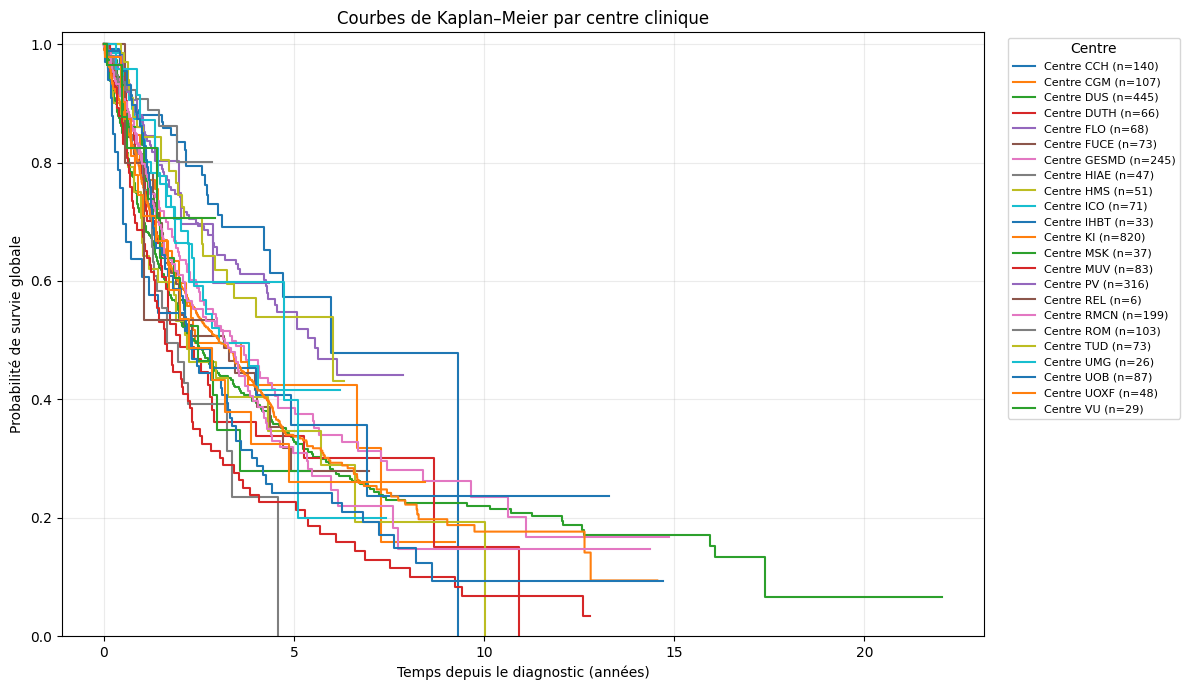

In [12]:
#courbes de kaplan meier par centre


fig, ax = plt.subplots(figsize=(12, 7))

# Chaque centre possède sa propre courbe
for center, groupe in dcli.groupby("CENTER"):

    # Exclure les observations dont le temps ou le statut est manquant
    groupe = groupe.dropna(subset=["OS_YEARS", "OS_STATUS"])

    if len(groupe) == 0:
        continue

    kmf.fit(
        durations=groupe["OS_YEARS"],
        event_observed=groupe["OS_STATUS"],
        label=f"Centre {center} (n={len(groupe)})"
    )

    kmf.plot_survival_function(
        ci_show=False,  #sinon c pas lisible
        ax=ax,
        show_censors=False
    )

ax.set_xlabel("Temps depuis le diagnostic (années)")
ax.set_ylabel("Probabilité de survie globale")
ax.set_title("Courbes de Kaplan–Meier par centre clinique")
ax.set_ylim(0, 1.02)
ax.grid(alpha=0.25)

# Légende à l'extérieur pour éviter de masquer les courbes
ax.legend(
    title="Centre",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    fontsize=8
)

plt.tight_layout()
plt.show()

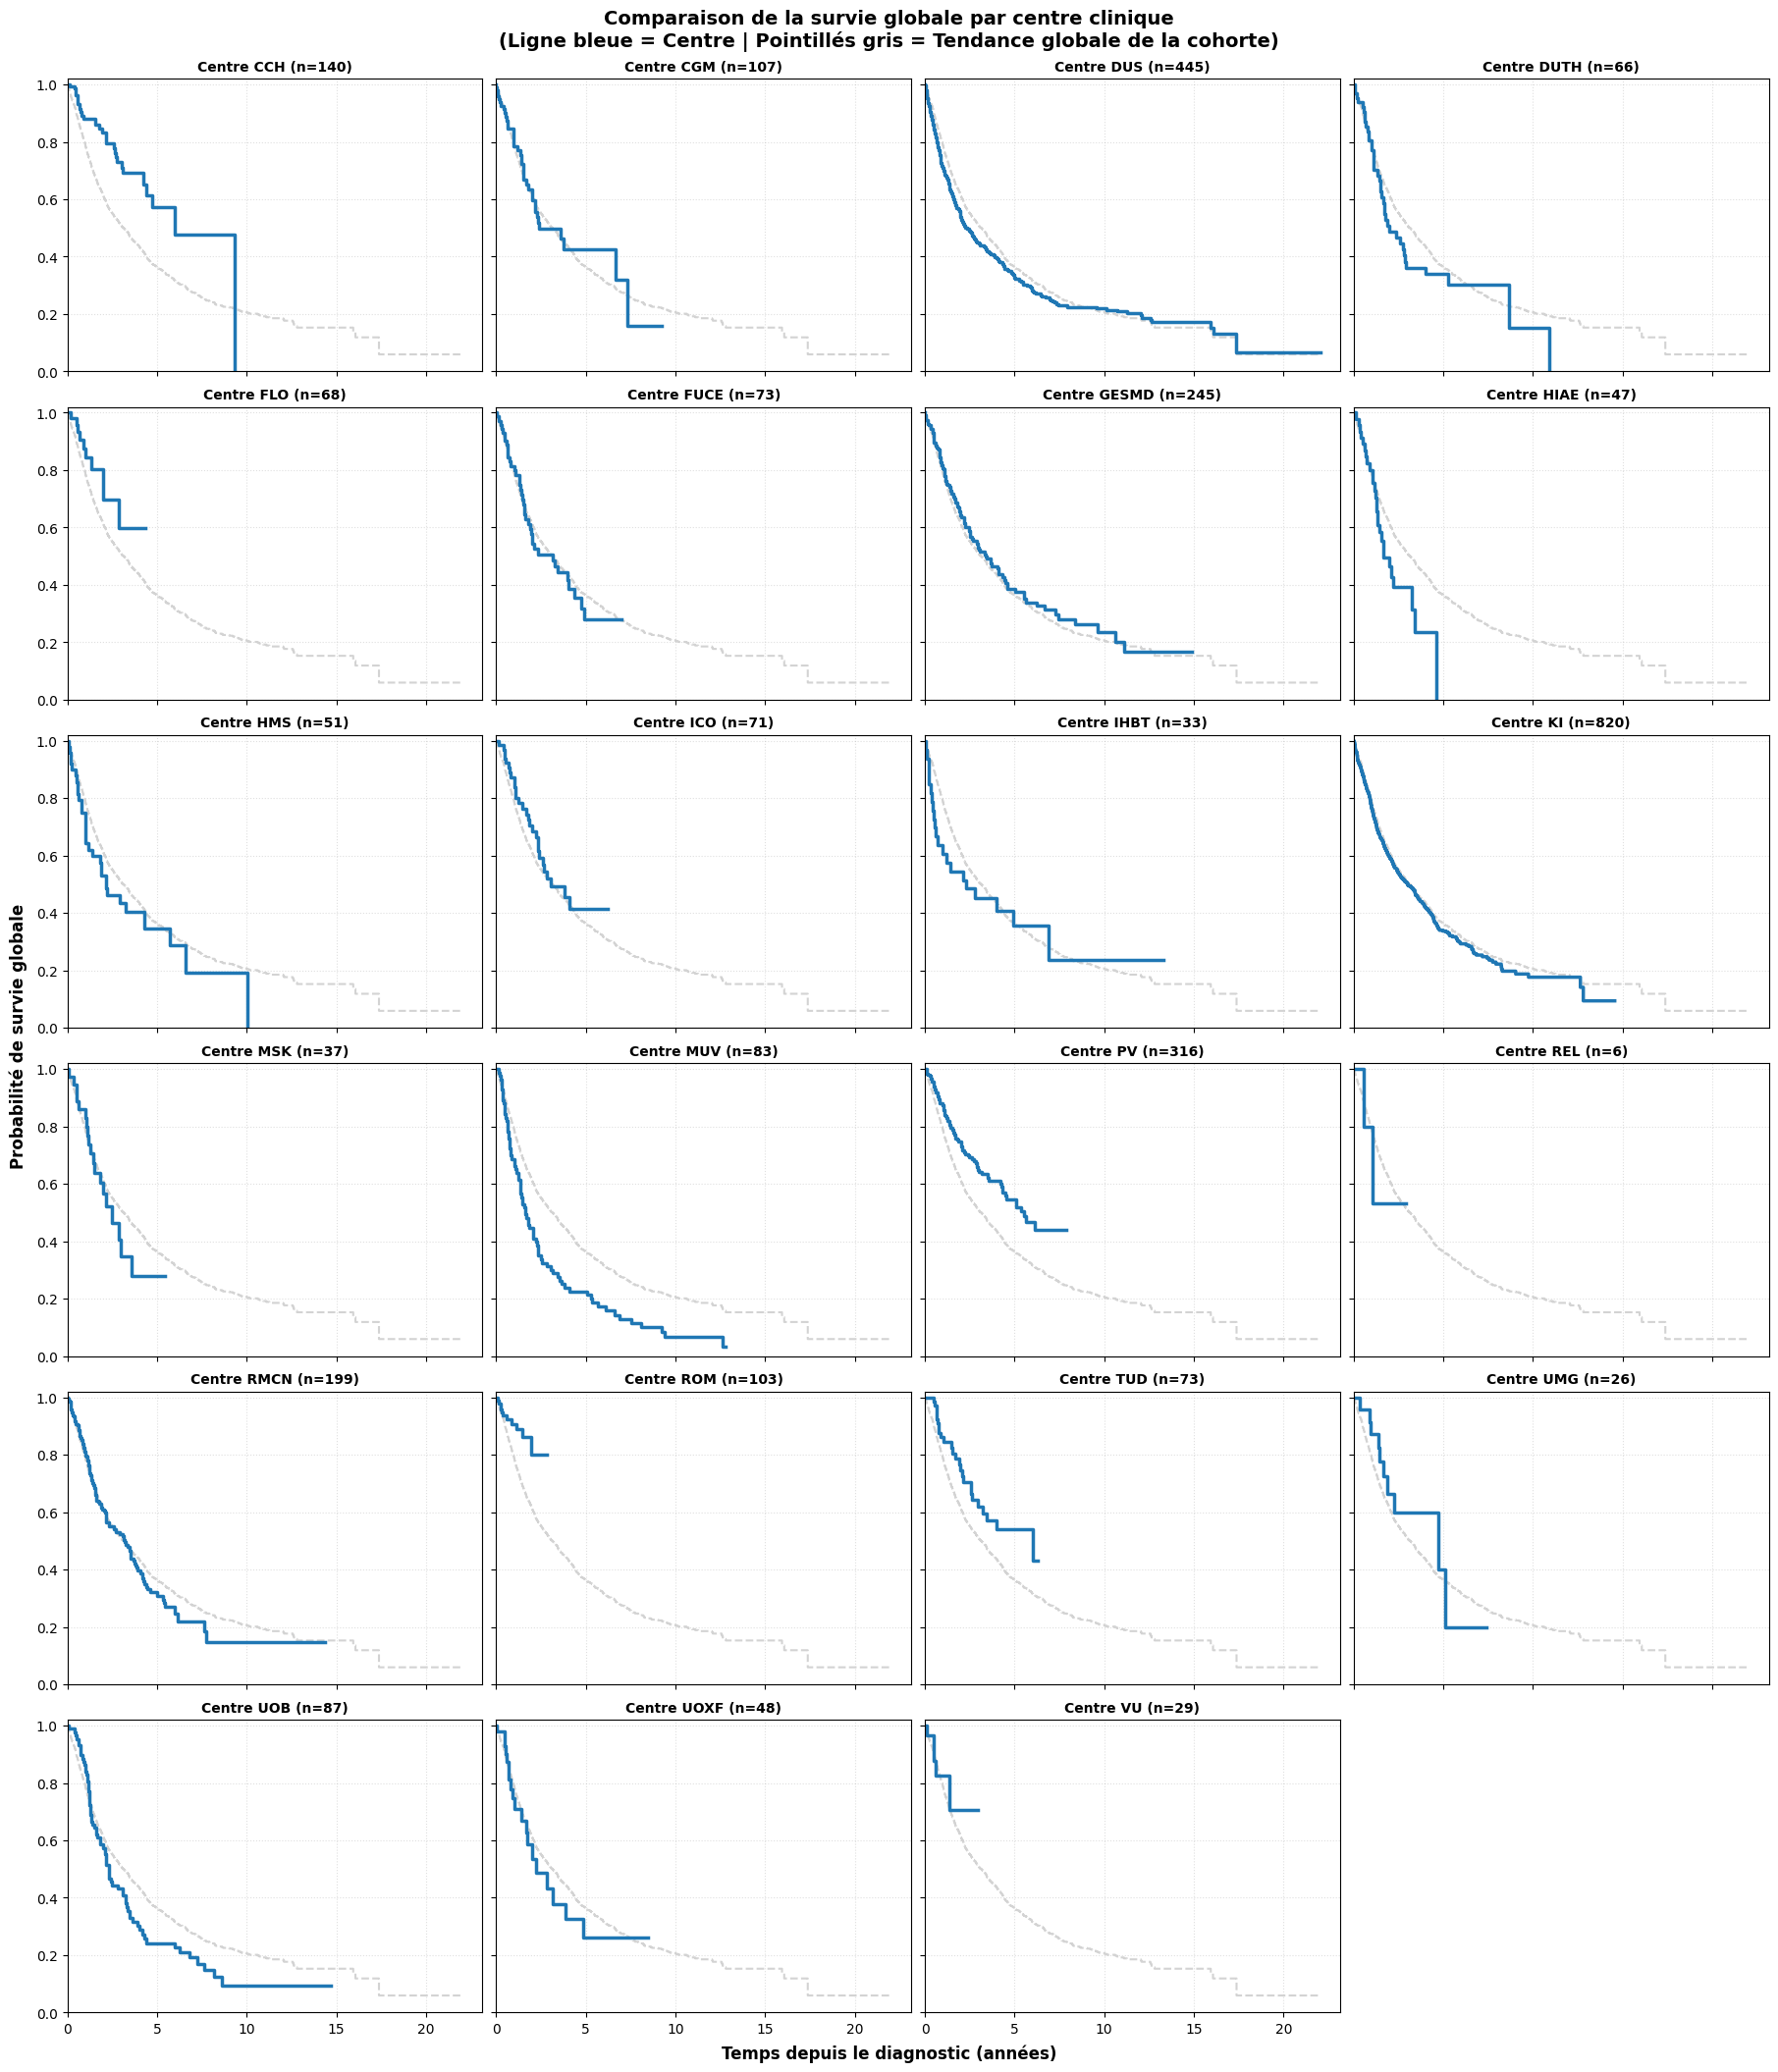

In [13]:
import math


# 1. Nettoyage initial des données globales
dcli_clean = dcli.dropna(subset=["CENTER", "OS_YEARS", "OS_STATUS"])
liste_centres = sorted(dcli_clean["CENTER"].unique())
n_centres = len(liste_centres)

# 2. Configuration de la grille dynamique
n_cols = 4
n_rows = math.ceil(n_centres / n_cols)

fig, axes = plt.subplots(
    n_rows, n_cols,
    figsize=(18, n_rows * 3.5),
    sharex=True, sharey=True,
    layout="constrained",  # gère suptitle, supxlabel, supylabel
)
axes = axes.flatten()

# 3. Courbe globale de référence (affichée en fond sur chaque mini-graphe)
kmf_global = KaplanMeierFitter()
kmf_global.fit(
    durations=dcli_clean["OS_YEARS"],
    event_observed=dcli_clean["OS_STATUS"],
)

x_max = dcli_clean["OS_YEARS"].max() * 1.05

# 4. Boucle de génération de la grille
for i, center in enumerate(liste_centres):
    ax = axes[i]
    groupe = dcli_clean[dcli_clean["CENTER"] == center]

    # A. Courbe globale en fond (gris clair, pointillés)
    kmf_global.plot_survival_function(
        ax=ax,
        ci_show=False,
        show_censors=False,
        color="#D3D3D3",
        linewidth=1.5,
        linestyle="--",
    )

    # B. Courbe spécifique du centre (en couleur)
    kmf = KaplanMeierFitter()
    kmf.fit(
        durations=groupe["OS_YEARS"],
        event_observed=groupe["OS_STATUS"],
    )
    kmf.plot_survival_function(
        ax=ax,
        ci_show=False,
        show_censors=False,
        color="#1f77b4",
        linewidth=2.5,
    )

    # C. Habillage de chaque sous-graphique
    ax.set_title(f"Centre {center} (n={len(groupe)})", fontsize=10, weight="bold")
    ax.grid(True, linestyle=":", alpha=0.4)
    ax.set_ylim(0, 1.02)
    ax.set_xlim(0, x_max)
    ax.set_xlabel("")  # évite les labels répétés (on utilise supxlabel)
    ax.legend_ = None  # retire les légendes individuelles

# 5. Supprime les axes vides en trop
for j in range(n_centres, len(axes)):
    fig.delaxes(axes[j])

# 6. Titres et labels globaux
fig.supxlabel("Temps depuis le diagnostic (années)", fontsize=12, weight="bold")
fig.supylabel("Probabilité de survie globale", fontsize=12, weight="bold")
fig.suptitle(
    "Comparaison de la survie globale par centre clinique\n"
    "(Ligne bleue = Centre | Pointillés gris = Tendance globale de la cohorte)",
    fontsize=14,
    weight="bold",
)

plt.show()

In [14]:
#logrank test
from lifelines.statistics import multivariate_logrank_test

# Données complètes pour les variables nécessaires

resultat = multivariate_logrank_test(
    event_durations=dcli_clean["OS_YEARS"],
    groups=dcli_clean["CENTER"],
    event_observed=dcli_clean["OS_STATUS"]
)

print(f"Statistique du log-rank : {resultat.test_statistic:.4f}")
print(f"Degrés de liberté : {dcli_clean['CENTER'].nunique() - 1}")
print(f"p-value : {resultat.p_value:.6g}")

Statistique du log-rank : 95.9888
Degrés de liberté : 22
p-value : 3.21432e-11


### Test du Log-Rank global entre centres cliniques

Le test global du Log-Rank met en évidence une **différence statistiquement significative** entre les fonctions de survie des 23 centres ($\chi^2 = 95.99$, $22$ degrés de liberté, $p = 3.21 \times 10^{-11}$).

L'hypothèse nulle d'égalité des fonctions de survie entre tous les centres :

$$H_0 : S_1(t) = S_2(t) = \dots = S_{23}(t) \quad \forall t \ge 0$$

est donc **rejetée au seuil de $5\%$**.

> **Remarque :** cette hétérogénéité reflète principalement des différences de recrutement et de gravité clinique ou moléculaire des patients entre centres (biais d'admission), ce qui motive l'ajustement sur les caractéristiques biologiques et mutationnelles individuelles.

---

## Traitement et agrégation de la base moléculaire (`df_mol`)

### Exploration de la fréquence des gènes mutés et des altérations protéiques

In [15]:
#afficher tous les elements et leur nombre
df_mol["GENE"].value_counts()

GENE
TET2       1663
ASXL1       951
SF3B1       775
DNMT3A      604
RUNX1       578
           ... 
PRPF40A       1
CDK4          1
NF2           1
RBBP4         1
JARID2        1
Name: count, Length: 124, dtype: int64

In [16]:
df_mol["PROTEIN_CHANGE"].value_counts()

PROTEIN_CHANGE
p.?                  529
p.K700E              426
p.G646fs*12          370
p.P95H               246
p.P95L               148
                    ... 
p.L1244P               1
p.R1571fs*25           1
p.A258fs*3             1
p.E856fs*7             1
p.L1151_G1152insE      1
Name: count, Length: 4686, dtype: int64

### Construction des variables moléculaires

Soit le multiensemble des mutations du patient $i$ :

$$\mathcal M_i = \lbrace (g_{i,k}, v_{i,k}, e_{i,k}) \rbrace_{k=1}^{K_i}$$

où $g \in \mathcal G$ désigne le gène, $v \in [0, 1]$ la fréquence allélique du variant (VAF), et $e \in \mathcal E$ la classe d'effet fonctionnel. On cherche une application d'agrégation :

$$\Phi : \mathcal P_{\mathrm{fini}}(\mathcal X_{\mathrm{mut}}) \to \mathbb R^q$$

telle que le vecteur de régression complet du patient $i$ soit :

$$X_i = \left( Z_i^\top, \Phi(\mathcal M_i)^\top \right)^\top$$

La table moléculaire contient plusieurs lignes par patient, car un patient peut présenter plusieurs mutations. Afin d'obtenir une seule observation par patient, les mutations sont agrégées en variables explicatives :

- **Indicatrice de mutation par gène** : pour chaque patient $i$ et chaque gène $g$, $\mathrm MUT_{i,g} = 1$ si au moins une mutation est détectée dans $g$, et $0$ sinon.
- **Nombre total de mutations** :

$$N_i = \sum_{j=1}^{m_i} 1 = m_i$$

où $m_i$ est le nombre de lignes moléculaires associées au patient $i$.

- **Fréquence allélique (VAF)** : moyenne, médiane, minimum et maximum des VAF observées chez le patient $i$, notés $\bar v_i$, $\mathrm{Med}(v_i)$, $\min(v_i)$ et $\max(v_i)$.
- **Profondeur de séquençage (DEPTH)** : moyenne $\bar d_i$ et médiane $\mathrm{Med}(d_i)$ de la profondeur de séquençage par patient.
- **Effet fonctionnel des mutations** : pour chaque catégorie d'effet $e \in \mathcal E$, on compte le nombre de mutations correspondantes :

$$N_{i,e} = \sum_{j=1}^{m_i} \mathbf{1}(\mathrm EFFECT_{i,j} = e)$$

Enfin, les variables obtenues sont regroupées dans une table contenant une seule ligne par patient, puis fusionnées avec les données cliniques et de survie à partir de l'identifiant `ID`.

In [21]:
#transformation de df_mol

# Copie de travail
mol = df_mol.copy()

# --------------------------------------------------
# 1. Nettoyage des identifiants et annotations
# --------------------------------------------------

mol["ID"] = mol["ID"].astype(str).str.strip()
mol["GENE"] = mol["GENE"].astype("string").str.strip()
mol["EFFECT"] = mol["EFFECT"].astype("string").str.strip()

# Conversion numérique
mol["VAF"] = pd.to_numeric(mol["VAF"], errors="coerce")
mol["DEPTH"] = pd.to_numeric(mol["DEPTH"], errors="coerce")

# --------------------------------------------------
# 2. Présence / absence de mutation par gène
# --------------------------------------------------

mol_gene = (
    mol.dropna(subset=["GENE"])
       .assign(value=1)
       .pivot_table(
           index="ID",
           columns="GENE",
           values="value",
           aggfunc="max",
           fill_value=0
       )
       .add_prefix("MUT_")
)

# --------------------------------------------------
# 3. Nombre total de mutations par patient
# --------------------------------------------------

mol_count = (
    mol.groupby("ID")
       .size()
       .rename("N_MUTATIONS")
       .to_frame()
)

# --------------------------------------------------
# 4. Statistiques des VAF et DEPTH
# --------------------------------------------------

mol_stats = mol.groupby("ID").agg(
    VAF_MEAN=("VAF", "mean"),
    VAF_MEDIAN=("VAF", "median"),
    VAF_MAX=("VAF", "max"),
    VAF_MIN=("VAF", "min"),
    DEPTH_MEAN=("DEPTH", "mean"),
    DEPTH_MEDIAN=("DEPTH", "median")
)

# --------------------------------------------------
# 5. Nombre de mutations par effet biologique
# --------------------------------------------------

mol_effect = (
    mol.dropna(subset=["EFFECT"])
       .assign(value=1)
       .pivot_table(
           index="ID",
           columns="EFFECT",
           values="value",
           aggfunc="sum",
           fill_value=0
       )
       .add_prefix("EFFECT_")
)

# --------------------------------------------------
# 6. Indicateur de présence de données moléculaires
# --------------------------------------------------

mol_presence = (
    mol.groupby("ID")
       .size()
       .gt(0)
       .astype(int)
       .rename("HAS_MOL_DATA")
       .to_frame()
)

# --------------------------------------------------
# 7. Fusion de toutes les informations
# --------------------------------------------------

mol_patient = (
    mol_gene
    .join(mol_count)
    .join(mol_stats)
    .join(mol_effect)
    .join(mol_presence)
    .reset_index()
)

# --------------------------------------------------
# 8. Vérifications
# --------------------------------------------------

print("Dimensions initiales :", df_mol.shape)
print("Dimensions transformées :", mol_patient.shape)

print("Nombre de patients :", mol_patient["ID"].nunique())
print("Doublons ID :", mol_patient["ID"].duplicated().sum())

#afficher avec skrub
display(TableReport(mol_patient))

Dimensions initiales : (10935, 11)
Dimensions transformées : (3026, 149)
Nombre de patients : 3026
Doublons ID : 0


<TableReport: use .open() to display>

In [22]:
# Répartition du nombre de mutations par patient
print(mol_patient["N_MUTATIONS"].describe())

# Nombre de gènes différents
print("Nombre de gènes :", len(mol_gene.columns))

# Répartition des effets
print(mol["EFFECT"].value_counts(dropna=False))

# Patients ayant plusieurs mutations
print(
    "Patients avec plusieurs mutations :",
    (mol_patient["N_MUTATIONS"] > 1).sum()
)

count    3026.000000
mean        3.613681
std         2.220222
min         1.000000
25%         2.000000
50%         3.000000
75%         5.000000
max        17.000000
Name: N_MUTATIONS, dtype: float64
Nombre de gènes : 124
EFFECT
non_synonymous_codon            5471
frameshift_variant              2877
stop_gained                     1673
splice_site_variant              512
inframe_codon_loss               168
PTD                               89
inframe_codon_gain                55
ITD                               26
initiator_codon_change            24
2KB_upstream_variant              12
complex_change_in_transcript      11
3_prime_UTR_variant                5
stop_lost                          4
inframe_variant                    4
synonymous_codon                   3
stop_retained_variant              1
Name: count, dtype: Int64
Patients avec plusieurs mutations : 2525


In [23]:
df_cox = dcli.merge(
    mol_patient,
    on="ID",
    how="left",
    validate="one_to_one"
)

### Protocole expérimental commun, Prétraitement de `df_cox` et Validation Croisée 5-Fold

Nous structurons l'apprentissage et l'évaluation sur la base fusionnée `df_cox` selon un protocole rigoureux sans fuite d'information :

#### 1. Traitement des patients sans mutation et du caryotype (`CYTOGENETICS`)
- Les **297 patients** de la base clinique absents de `df_mol` n'ont aucune mutation somatique détectée : leurs variables moléculaires (`HAS_MOL_DATA`, `N_MUTATIONS`, `MUT_*`, `EFFECT_*`, `VAF_*`) sont imputées à `0`.
- Afin d'éviter la quasi-colinéarité dans le modèle de Cox (où 31 gènes apparaissent chez moins de 5 patients) et la colinéarité exacte entre `N_MUTATIONS` et la somme des `EFFECT_*`, les gènes mutés chez au moins 30 patients ($\ge 1\text{ \%}$) sont conservés individuellement et les gènes rares sont regroupés dans une indicatrice `MUT_RARE_OTHER`.
- Des descripteurs cytogénétiques binaires (`CYTO_MISSING`, `CYTO_NORMAL`, `CYTO_DEL5`, `CYTO_DEL7`, `CYTO_TRIS8`, `CYTO_COMPLEX`) sont extraits de la chaîne ISCN `CYTOGENETICS`.

#### 2. Partition externe et Validation Croisée Stratifiée à 5 plis (`StratifiedKFold`)
- Le jeu de données complet ($n = 3\,173$ patients avec cible observée) est divisé une seule fois en **80 % d'entraînement ($n = 2\,538$)** et **20 % de test externe gelé ($n = 635$)**, avec stratification sur l'indicateur d'événement `OS_STATUS` (`random_state = 42`).
- Sur l'ensemble d'entraînement ($n = 2\,538$), nous mettons en place une **validation croisée stratifiée à $K = 5$ plis** (`StratifiedKFold(n_splits=5)` sur `OS_STATUS`) :
  - À l'intérieur de chaque pli $k \in \lbrace 1, \dots, 5\rbrace $, l'imputation médiane, la standardisation (`StandardScaler`) ainsi que les grilles temporelles de PC-Hazard sont estimées **exclusivement sur les 4 plis d'apprentissage** et appliquées au pli de validation correspondant.
  - Les hyperparamètres et les époques d'*early stopping* sont sélectionnés par maximisation de la moyenne sur les 5 plis du **C-index IPCW de Uno**.
  - Chaque modèle retenu est ensuite **ré-entraîné sur les 100 % du Train** ($n = 2\,538$) avant son évaluation unique sur le **Test externe**.

#### 3. Critères d'évaluation (Discrimination et Précision probabiliste)

- **C-index de Harrell** sur l'ensemble des paires comparables $\mathcal E = \lbrace (i,j) : \Delta_i = 1,\ Y_i < Y_j\rbrace $ :

$$C = \frac{1}{|\mathcal E|} \sum_{(i,j) \in \mathcal E} \mathbf{1}\lbrace g(X_i) > g(X_j)\rbrace$$

- **C-index d'Uno pondéré par l'inverse de la probabilité de censure (IPCW)** à l'horizon officiel du challenge $\tau = 7\text{ ans}$ :

$$\hat C_{\mathrm{Uno}}(\tau) = \frac{\sum_{i=1}^n \sum_{j=1}^n \Delta_i \, \mathbf{1}\lbrace Y_i < Y_j\rbrace  \, \mathbf{1}\lbrace Y_i \le \tau\rbrace  \, \hat S_C(Y_i)^{-2} \, \mathbf{1}\lbrace g(X_i) > g(X_j)\rbrace }{\sum_{i=1}^n \sum_{j=1}^n \Delta_i \, \mathbf{1}\lbrace Y_i < Y_j\rbrace  \, \mathbf{1}\lbrace Y_i \le \tau\rbrace  \, \hat S_C(Y_i)^{-2}}$$

- **Score de Brier** $\mathrm{BS}(t)$ et **Score de Brier intégré (IBS)** sur une grille de 100 temps régulièrement espacés entre les quantiles 5 % et 95 % des temps d'événement :

$$\mathrm{BS}(t) = \frac{1}{n}\sum_{i=1}^n \left[ \frac{\widehat{S}(t \mid X_i)^2 \, \Delta_i \, \mathbf{1}\lbrace Y_i \le t\rbrace }{\hat S_C(Y_i)} + \frac{\left(1 - \widehat{S}(t \mid X_i)\right)^2 \, \mathbf{1}\lbrace Y_i > t\rbrace }{\hat S_C(t)} \right]$$

$$\mathrm{IBS} = \frac{1}{t_{\max} - t_{\min}} \int_{t_{\min}}^{t_{\max}} \mathrm{BS}(u)\,du$$

In [20]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from lifelines import KaplanMeierFitter, NelsonAalenFitter, CoxPHFitter
from lifelines.statistics import proportional_hazard_test
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sksurv.util import Surv
from sksurv.metrics import (
    concordance_index_censored,
    concordance_index_ipcw,
    integrated_brier_score,
    brier_score,
)
from sksurv.tree import SurvivalTree
from sksurv.ensemble import RandomSurvivalForest, GradientBoostingSurvivalAnalysis

# 1. Nettoyage de la cible (OS_YEARS, OS_STATUS)
df_clean = df_cox.dropna(subset=["OS_YEARS", "OS_STATUS"]).copy()
df_clean["OS_YEARS"] = pd.to_numeric(df_clean["OS_YEARS"], errors="coerce").clip(lower=1e-4)
df_clean["OS_STATUS"] = df_clean["OS_STATUS"].astype(int)

# 2. Imputation à 0 des 297 patients sans mutation détectée dans df_mol
mut_cols = [c for c in df_clean.columns if c.startswith("MUT_")]
effect_cols = [c for c in df_clean.columns if c.startswith("EFFECT_")]
mol_zero_cols = ["HAS_MOL_DATA", "N_MUTATIONS", "VAF_MEAN", "VAF_MEDIAN", "VAF_MAX", "VAF_MIN"] + mut_cols + effect_cols
df_clean[mol_zero_cols] = df_clean[mol_zero_cols].fillna(0)
df_clean[["DEPTH_MEAN", "DEPTH_MEDIAN"]] = df_clean[["DEPTH_MEAN", "DEPTH_MEDIAN"]].fillna(0)

# 3. Extraction d'indicateurs cytogénétiques simples à partir de CYTOGENETICS (ISCN)
cyto_str = df_clean["CYTOGENETICS"].fillna("").astype(str).str.lower()
df_clean["CYTO_MISSING"] = (cyto_str == "").astype(float)
df_clean["CYTO_NORMAL"] = cyto_str.str.contains(r"^46,xx\[|^46,xy\[|^46,xx$|^46,xy$", regex=True).astype(float)
df_clean["CYTO_DEL5"] = cyto_str.str.contains(r"-5|del\(5", regex=True).astype(float)
df_clean["CYTO_DEL7"] = cyto_str.str.contains(r"-7|del\(7", regex=True).astype(float)
df_clean["CYTO_TRIS8"] = cyto_str.str.contains(r"\+8", regex=True).astype(float)
df_clean["CYTO_COMPLEX"] = (cyto_str.str.count(r",|\+|del|inv|t\(|der") >= 4).astype(float)

# 4. Regroupement des gènes rares (< 30 patients) dans MUT_RARE_OTHER
gene_freq = df_clean[mut_cols].sum(axis=0)
frequent_genes = gene_freq[gene_freq >= 30].index.tolist()
rare_genes = gene_freq[gene_freq < 30].index.tolist()
df_clean["MUT_RARE_OTHER"] = (df_clean[rare_genes].sum(axis=1) > 0).astype(float)

effect_freq = df_clean[effect_cols].sum(axis=0)
frequent_effects = effect_freq[effect_freq >= 50].index.tolist()
kept_effects = [c for c in frequent_effects if c != "EFFECT_synonymous_codon"][:6]

clinical_num_cols = ["BM_BLAST", "WBC", "ANC", "MONOCYTES", "HB", "PLT"]
cyto_cols = ["CYTO_MISSING", "CYTO_NORMAL", "CYTO_DEL5", "CYTO_DEL7", "CYTO_TRIS8", "CYTO_COMPLEX"]
mol_summary_cols = ["HAS_MOL_DATA", "N_MUTATIONS", "VAF_MEAN", "VAF_MAX", "MUT_RARE_OTHER"]
feature_cols = clinical_num_cols + cyto_cols + mol_summary_cols + kept_effects + frequent_genes

print(f"Nombre total de patients analysables : {len(df_clean)}")
print(f"Taux d'événement (décès OS_STATUS=1) : {df_clean['OS_STATUS'].mean():.3f} ({df_clean['OS_STATUS'].sum()} décès)")
print(f"Nombre de gènes fréquents (>= 30 patients) : {len(frequent_genes)} / {len(mut_cols)} (gènes rares regroupés dans MUT_RARE_OTHER)")
print(f"Dimension finale du vecteur de covariables X_i : p = {len(feature_cols)}")

# 5. Partition externe commune 80% Train / 20% Test stratifiée sur OS_STATUS
df_train, df_test = train_test_split(df_clean, test_size=0.20, stratify=df_clean["OS_STATUS"], random_state=42)
t_max_train = df_train["OS_YEARS"].max()
df_test_eval = df_test.loc[df_test["OS_YEARS"] < t_max_train].copy()
print(f"Partition externe : Train = {len(df_train)} | Test externe évalué = {len(df_test_eval)}")

# Imputation médiane et Standardisation sur l'entraînement complet (pour les modèles finaux)
imputer = SimpleImputer(strategy="median")
scaler = StandardScaler()
X_train_raw = pd.DataFrame(imputer.fit_transform(df_train[feature_cols]), columns=feature_cols, index=df_train.index)
X_test_raw = pd.DataFrame(imputer.transform(df_test_eval[feature_cols]), columns=feature_cols, index=df_test_eval.index)
X_train_std = pd.DataFrame(scaler.fit_transform(X_train_raw), columns=feature_cols, index=df_train.index)
X_test_std = pd.DataFrame(scaler.transform(X_test_raw), columns=feature_cols, index=df_test_eval.index)

y_train_surv = Surv.from_dataframe("OS_STATUS", "OS_YEARS", df_train)
y_test_surv = Surv.from_dataframe("OS_STATUS", "OS_YEARS", df_test_eval)

t_min_ibs = float(np.quantile(df_train.loc[df_train["OS_STATUS"] == 1, "OS_YEARS"], 0.05))
t_max_ibs = min(float(np.quantile(df_train.loc[df_train["OS_STATUS"] == 1, "OS_YEARS"], 0.95)), float(df_test_eval["OS_YEARS"].max()) * 0.98)
IBS_TIMES = np.linspace(t_min_ibs, t_max_ibs, 100)
TAU_QRT = 7.0

# 6. Préparation des 5 plis stratifiés (StratifiedKFold) sans fuite d'information
N_FOLDS = 5
skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=42)
cv_folds = []
for fold_id, (tr_idx, va_idx) in enumerate(skf.split(df_train, df_train["OS_STATUS"])):
    df_tr_f = df_train.iloc[tr_idx]
    df_va_raw_f = df_train.iloc[va_idx]
    t_max_f = float(df_tr_f["OS_YEARS"].max())
    df_va_eval_f = df_va_raw_f.loc[df_va_raw_f["OS_YEARS"] < t_max_f].copy()

    imp_f = SimpleImputer(strategy="median")
    scl_f = StandardScaler()
    X_tr_raw_f = pd.DataFrame(imp_f.fit_transform(df_tr_f[feature_cols]), columns=feature_cols, index=df_tr_f.index)
    X_va_raw_f = pd.DataFrame(imp_f.transform(df_va_raw_f[feature_cols]), columns=feature_cols, index=df_va_raw_f.index)
    X_va_eval_raw_f = pd.DataFrame(imp_f.transform(df_va_eval_f[feature_cols]), columns=feature_cols, index=df_va_eval_f.index)
    X_tr_std_f = pd.DataFrame(scl_f.fit_transform(X_tr_raw_f), columns=feature_cols, index=df_tr_f.index)
    X_va_std_f = pd.DataFrame(scl_f.transform(X_va_raw_f), columns=feature_cols, index=df_va_raw_f.index)
    X_va_eval_std_f = pd.DataFrame(scl_f.transform(X_va_eval_raw_f), columns=feature_cols, index=df_va_eval_f.index)

    t_min_f = float(np.quantile(df_tr_f.loc[df_tr_f["OS_STATUS"] == 1, "OS_YEARS"], 0.05))
    t_max_ibs_f = min(float(np.quantile(df_tr_f.loc[df_tr_f["OS_STATUS"] == 1, "OS_YEARS"], 0.95)), float(df_va_eval_f["OS_YEARS"].max()) * 0.98)
    ibs_times_f = np.linspace(t_min_f, t_max_ibs_f, 100)

    cv_folds.append({
        "fold": fold_id + 1,
        "df_tr": df_tr_f,
        "df_va": df_va_raw_f,
        "df_va_eval": df_va_eval_f,
        "X_tr_raw": X_tr_raw_f,
        "X_va_raw": X_va_raw_f,
        "X_va_eval_raw": X_va_eval_raw_f,
        "X_tr_std": X_tr_std_f,
        "X_va_std": X_va_std_f,
        "X_va_eval_std": X_va_eval_std_f,
        "y_tr_surv": Surv.from_dataframe("OS_STATUS", "OS_YEARS", df_tr_f),
        "y_va_surv": Surv.from_dataframe("OS_STATUS", "OS_YEARS", df_va_raw_f),
        "y_va_eval_surv": Surv.from_dataframe("OS_STATUS", "OS_YEARS", df_va_eval_f),
        "ibs_times": ibs_times_f,
    })

print(f"Validation croisée 5-Fold stratifiée initialisée ({[len(f['df_va_eval']) for f in cv_folds]} patients évalués par pli).")
print(f"Grille d'évaluation Test IBS : 100 points sur [{t_min_ibs:.3f}, {t_max_ibs:.3f}] ans | Horizon Uno IPCW tau = {TAU_QRT} ans")

def eval_fold_metrics(y_tr_s, y_va_s, risk_va, surv_va, ibs_times_f):
    c_har = concordance_index_censored(y_va_s["OS_STATUS"], y_va_s["OS_YEARS"], risk_va)[0]
    c_uno = concordance_index_ipcw(y_tr_s, y_va_s, risk_va, tau=TAU_QRT)[0]
    ibs_v = integrated_brier_score(y_tr_s, y_va_s, np.clip(surv_va, 1e-6, 1.0 - 1e-6), ibs_times_f)
    return c_har, c_uno, ibs_v

def evaluate_survival_model(name, category, risk_scores_test, surv_matrix_test, cv_stats=None):
    c_harrell = concordance_index_censored(y_test_surv["OS_STATUS"], y_test_surv["OS_YEARS"], risk_scores_test)[0]
    c_uno = concordance_index_ipcw(y_train_surv, y_test_surv, risk_scores_test, tau=TAU_QRT)[0]
    surv_clipped = np.clip(surv_matrix_test, 1e-6, 1.0 - 1e-6)
    ibs_val = integrated_brier_score(y_train_surv, y_test_surv, surv_clipped, IBS_TIMES)
    _, bs_curve = brier_score(y_train_surv, y_test_surv, surv_clipped, IBS_TIMES)
    return {
        "Modèle": name,
        "Catégorie": category,
        "CV Harrell Mean": cv_stats["har_mean"] if cv_stats else np.nan,
        "CV Harrell Std": cv_stats["har_std"] if cv_stats else np.nan,
        "CV Uno Mean": cv_stats["uno_mean"] if cv_stats else np.nan,
        "CV Uno Std": cv_stats["uno_std"] if cv_stats else np.nan,
        "CV IBS Mean": cv_stats["ibs_mean"] if cv_stats else np.nan,
        "CV IBS Std": cv_stats["ibs_std"] if cv_stats else np.nan,
        "C-index Harrell": c_harrell,
        "C-index Uno (IPCW)": c_uno,
        "IBS": ibs_val,
        "bs_curve": bs_curve,
        "surv_matrix": surv_clipped,
        "risk_scores": risk_scores_test,
    }

Nombre total de patients analysables : 3173
Taux d'événement (décès OS_STATUS=1) : 0.504 (1600 décès)
Nombre de gènes fréquents (>= 30 patients) : 50 / 124 (gènes rares regroupés dans MUT_RARE_OTHER)
Dimension finale du vecteur de covariables X_i : p = 73
Partition externe : Train = 2538 | Test externe évalué = 631
Validation croisée 5-Fold stratifiée initialisée ([508, 508, 507, 507, 507] patients évalués par pli).
Grille d'évaluation Test IBS : 100 points sur [0.137, 5.777] ans | Horizon Uno IPCW tau = 7.0 ans


### 1. Modèle de référence (Benchmark) : Modèle de Cox à risques proportionnels et Test de Schoenfeld

#### Formulation et vraisemblance partielle de Cox
Le modèle de Cox sert de **référence statistique semi-paramétrique** (benchmark). Il suppose que le risque instantané conditionnel s'écrit :

$$h(t \mid x) = h_0(t)\exp\left(x^\top \beta\right)$$

de sorte que le rapport des risques entre deux profils $x$ et $x'$ ne dépend pas du temps $t$ :

$$\frac{h(t \mid x)}{h(t \mid x')} = \exp\left((x - x')^\top \beta\right)$$

Le vecteur $\beta \in \mathbb{R}^p$ est estimé en minimisant l'opposé de la log-vraisemblance partielle sur les ensembles à risque $R(Y_i) = \lbrace j : Y_j \ge Y_i\rbrace $ :

$$\mathcal L_{\mathrm{Cox}}(\beta) = -\ell_p(\beta) = -\sum_{i : \Delta_i = 1} \left[ X_i^\top \beta - \log\left(\sum_{j \in R(Y_i)} \exp\left(X_j^\top \beta\right)\right) \right]$$

La fonction de survie est ensuite reconstruite via l'estimateur de Breslow $\hat H_0(t)$ :

$$\hat H_0(t) = \sum_{\ell : \tau_\ell \le t} \frac{d_\ell}{\sum_{j \in R(\tau_\ell)} \exp\left(X_j^\top \widehat{\beta}\right)}, \qquad \widehat{S}(t \mid x) = \exp\left(-\hat H_0(t)\exp\left(x^\top \widehat{\beta}\right)\right)$$

---

#### Remarque sur les résidus de Schoenfeld et le test des risques proportionnels
L'hypothèse des risques proportionnels impose que l'effet $\beta_k$ de chaque covariable $k$ soit constant dans le temps. Pour vérifier cette hypothèse, on compare à chaque temps d'événement $t$ la covariable observée $X_i$ de l'individu qui subit l'événement à son espérance conditionnelle sous le modèle de Cox parmi les individus encore à risque $R(t)$ :

$$\mathbb E_{\widehat{\beta}}[X_{J_t} \mid R(t)] = \frac{\sum_{j \in R(t)} X_j \exp\left(\widehat{\beta}^\top X_j\right)}{\sum_{j \in R(t)} \exp\left(\widehat{\beta}^\top X_j\right)}$$

Le **résidu de Schoenfeld** au temps d'événement $t$ est alors défini par le vecteur :

$$r(t) = X_i - \mathbb E_{\widehat{\beta}}[X_{J_t} \mid R(t)] \in \mathbb{R}^p$$

Pour chaque covariable $k \in \lbrace 1, \dots, p\rbrace $, on teste l'hypothèse nulle $H_0^{(k)}$ (« l'effet de la covariable $k$ est constant au cours du temps ») à l'aide de la régression auxiliaire :

$$r_k(t) = a_k + b_k q(t) + \varepsilon_t$$

où $q(t)$ est une transformation du temps (ici le rang du temps d'événement), et l'on teste $b_k = 0$ :
- **Absence de tendance temporelle ($b_k \approx 0$)** : l'hypothèse des risques proportionnels est plausible.
- **Tendance temporelle significative ($b_k \neq 0$, $p < 0{,}05$)** : l'effet pronostique varie au cours du temps. En leucémie myéloïde aiguë, certaines altérations moléculaires (`MUT_NPM1`, `MUT_U2AF1`, `MUT_WT1`) et variables hématologiques (`PLT`) ont un impact pronostique très marqué dans la phase initiale suivant le diagnostic qui évolue chez les survivants à long terme, ce qui motive le recours à des modèles flexibles (forêts de survie, PC-Hazard).

=== Modèle de Cox (Référence, penalizer=0.1) ===
CV 5-Fold Harrell       : 0.7252 ± 0.0119
CV 5-Fold Uno (tau=7ans): 0.7021 ± 0.0170
CV 5-Fold IBS           : 0.1677 ± 0.0056
Test Externe Harrell    : 0.7284
Test Externe Uno        : 0.7089
Test Externe IBS        : 0.1670

=== Test des résidus de Schoenfeld (transformation du temps q(t) = rang) ===
Variables rejetant l'hypothèse de risques proportionnels H_0^(k): b_k = 0 au seuil de 5% : 7 / 73

Top 10 des variables présentant la plus forte dérive temporelle des résidus de Schoenfeld :
           test_statistic       p  -log2(p)
MUT_NPM1          16.9037  0.0000   14.6342
PLT                7.6381  0.0057    7.4511
MUT_U2AF1          6.7317  0.0095    6.7222
MUT_TP53           5.8565  0.0155    6.0097
MUT_WT1            5.3459  0.0208    5.5893
MUT_SF3B1          4.6029  0.0319    4.9695
MUT_KMT2D          4.1889  0.0407    4.6192
MUT_JAK2           3.6496  0.0561    4.1563
MUT_U2AF2          3.5671  0.0589    4.0847
MUT_DDX41        

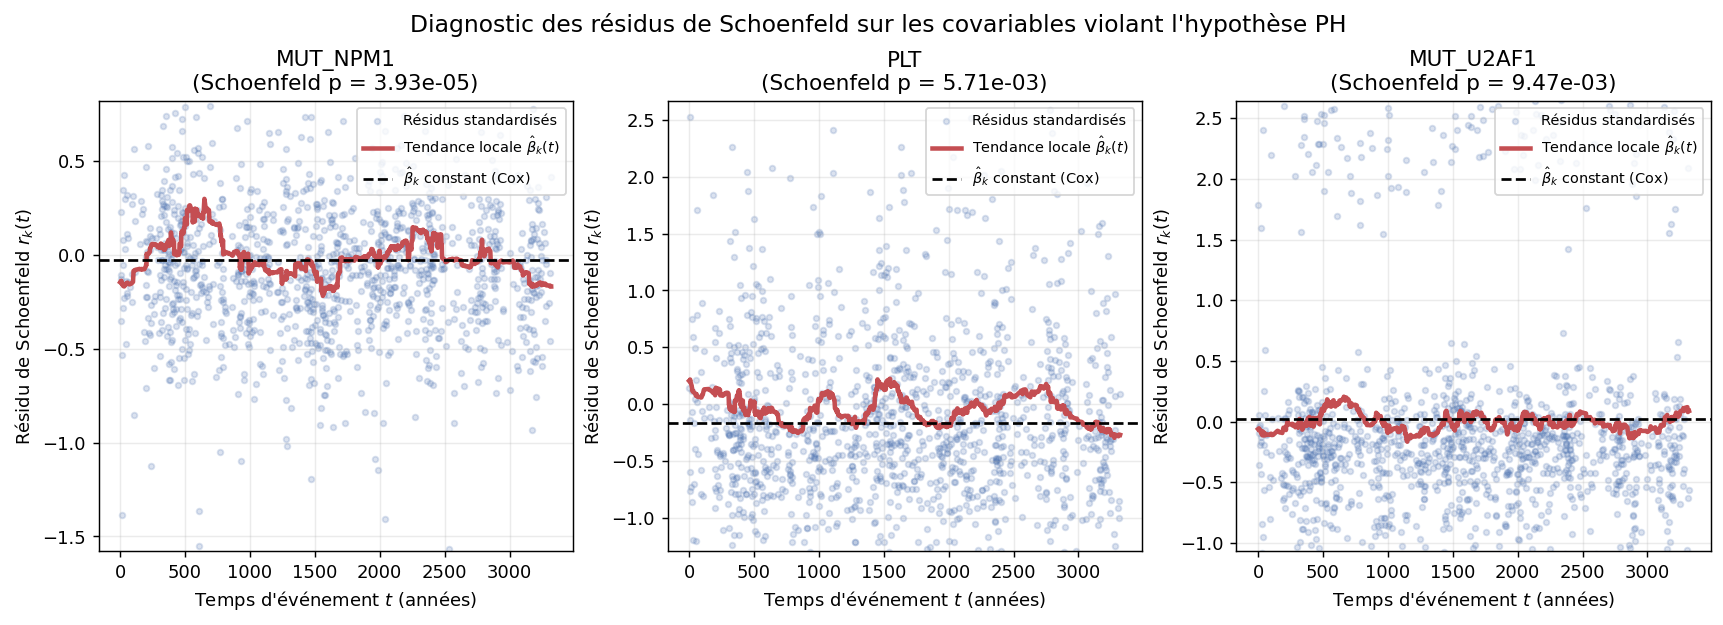

In [21]:
# 1. Validation croisée 5-Fold pour le pénalisateur L2 du modèle de Cox
best_cox_pen = None
best_cox_cv = None
best_cox_uno_cv = -1.0

for pen in [0.005, 0.01, 0.05, 0.1]:
    fold_metrics = []
    for f in cv_folds:
        df_tr_ll = f["X_tr_std"].copy()
        df_tr_ll["OS_YEARS"] = f["df_tr"]["OS_YEARS"].values
        df_tr_ll["OS_STATUS"] = f["df_tr"]["OS_STATUS"].values
        cph_f = CoxPHFitter(penalizer=pen)
        cph_f.fit(df_tr_ll, duration_col="OS_YEARS", event_col="OS_STATUS")
        r_va = cph_f.predict_log_partial_hazard(f["X_va_eval_std"]).values
        s_va = cph_f.predict_survival_function(f["X_va_eval_std"], times=f["ibs_times"]).T.values
        fold_metrics.append(eval_fold_metrics(f["y_tr_surv"], f["y_va_eval_surv"], r_va, s_va, f["ibs_times"]))
    arr = np.array(fold_metrics)
    if arr[:, 1].mean() > best_cox_uno_cv:
        best_cox_uno_cv = arr[:, 1].mean()
        best_cox_pen = pen
        best_cox_cv = {
            "har_mean": arr[:, 0].mean(), "har_std": arr[:, 0].std(),
            "uno_mean": arr[:, 1].mean(), "uno_std": arr[:, 1].std(),
            "ibs_mean": arr[:, 2].mean(), "ibs_std": arr[:, 2].std(),
        }

# Ajustement final sur 100% du Train
df_lifelines_train = X_train_std.copy()
df_lifelines_train["OS_YEARS"] = df_train["OS_YEARS"].values
df_lifelines_train["OS_STATUS"] = df_train["OS_STATUS"].values

cph = CoxPHFitter(penalizer=best_cox_pen)
cph.fit(df_lifelines_train, duration_col="OS_YEARS", event_col="OS_STATUS")

cox_risk_test = cph.predict_log_partial_hazard(X_test_std).values
cox_surv_df = cph.predict_survival_function(X_test_std, times=IBS_TIMES)
cox_surv_matrix = cox_surv_df.T.values

res_cox = evaluate_survival_model("Cox (Référence)", "Référence statistique", cox_risk_test, cox_surv_matrix, cv_stats=best_cox_cv)
print(f"=== Modèle de Cox (Référence, penalizer={best_cox_pen}) ===")
print(f"CV 5-Fold Harrell       : {best_cox_cv['har_mean']:.4f} ± {best_cox_cv['har_std']:.4f}")
print(f"CV 5-Fold Uno (tau=7ans): {best_cox_cv['uno_mean']:.4f} ± {best_cox_cv['uno_std']:.4f}")
print(f"CV 5-Fold IBS           : {best_cox_cv['ibs_mean']:.4f} ± {best_cox_cv['ibs_std']:.4f}")
print(f"Test Externe Harrell    : {res_cox['C-index Harrell']:.4f}")
print(f"Test Externe Uno        : {res_cox['C-index Uno (IPCW)']:.4f}")
print(f"Test Externe IBS        : {res_cox['IBS']:.4f}\n")

# 2. Test des résidus de Schoenfeld
ph_test = proportional_hazard_test(cph, df_lifelines_train, time_transform="rank")
ph_summary = ph_test.summary.sort_values("p")
violated = ph_summary[ph_summary["p"] < 0.05]

print("=== Test des résidus de Schoenfeld (transformation du temps q(t) = rang) ===")
print(f"Variables rejetant l'hypothèse de risques proportionnels H_0^(k): b_k = 0 au seuil de 5% : {len(violated)} / {len(feature_cols)}")
print("\nTop 10 des variables présentant la plus forte dérive temporelle des résidus de Schoenfeld :")
print(ph_summary[["test_statistic", "p", "-log2(p)"]].head(10).round(4).to_string())

# 3. Comparaison avec transformation log(1+x) sur les variables cliniques asymétriques
skew_cols = ["BM_BLAST", "WBC", "ANC", "MONOCYTES", "PLT"]
X_train_log = X_train_raw.copy()
X_test_log = X_test_raw.copy()
for col in skew_cols:
    X_train_log[col] = np.log1p(np.maximum(0, X_train_log[col]))
    X_test_log[col] = np.log1p(np.maximum(0, X_test_log[col]))

scaler_log = StandardScaler()
X_train_log_std = pd.DataFrame(scaler_log.fit_transform(X_train_log), columns=feature_cols, index=df_train.index)
X_test_log_std = pd.DataFrame(scaler_log.transform(X_test_log), columns=feature_cols, index=df_test_eval.index)

df_ll_log = X_train_log_std.copy()
df_ll_log["OS_YEARS"] = df_train["OS_YEARS"].values
df_ll_log["OS_STATUS"] = df_train["OS_STATUS"].values
cph_log = CoxPHFitter(penalizer=best_cox_pen)
cph_log.fit(df_ll_log, duration_col="OS_YEARS", event_col="OS_STATUS")
cox_log_risk = cph_log.predict_log_partial_hazard(X_test_log_std).values
c_uno_log = concordance_index_ipcw(y_train_surv, y_test_surv, cox_log_risk, tau=TAU_QRT)[0]
c_har_log = concordance_index_censored(y_test_surv["OS_STATUS"], y_test_surv["OS_YEARS"], cox_log_risk)[0]
print(f"\nComparaison Cox avec log1p sur variables cliniques asymétriques -> Harrell: {c_har_log:.4f} | Uno IPCW: {c_uno_log:.4f}")

# 4. Graphique des résidus de Schoenfeld pour les 3 covariables les plus significatives
schoenfeld_res = cph.compute_residuals(df_lifelines_train, kind="scaled_schoenfeld")
top3_vars = ph_summary.index[:3].tolist()
fig_sch, axes_sch = plt.subplots(1, 3, figsize=(16, 4.5))
event_times = schoenfeld_res.index.values

for ax, var_name in zip(axes_sch, top3_vars):
    y_res = schoenfeld_res[var_name].values
    ax.scatter(event_times, y_res, alpha=0.2, s=10, color="#4C72B0", label="Résidus standardisés")
    order = np.argsort(event_times)
    t_ord, y_ord = event_times[order], y_res[order]
    win = max(30, len(t_ord) // 12)
    y_smooth = pd.Series(y_ord).rolling(win, center=True, min_periods=10).mean().values
    ax.plot(t_ord, y_smooth, color="#C44E52", lw=2.5, label=r"Tendance locale $\hat{\beta}_k(t)$")
    ax.axhline(cph.params_[var_name], color="black", ls="--", lw=1.5, label=r"$\hat{\beta}_k$ constant (Cox)")
    pval = ph_summary.loc[var_name, "p"]
    ax.set_title(f"{var_name}\n(Schoenfeld p = {pval:.2e})")
    ax.set_xlabel("Temps d'événement $t$ (années)")
    ax.set_ylabel(r"Résidu de Schoenfeld $r_k(t)$")
    ax.set_ylim(np.percentile(y_res, 2), np.percentile(y_res, 98))
    ax.legend(fontsize=8, loc="upper right")
    ax.grid(alpha=0.25)

fig_sch.suptitle("Diagnostic des résidus de Schoenfeld sur les covariables violant l'hypothèse PH", fontsize=13, y=1.03)
plt.show()

### 2. Arbre de survie et Forêt aléatoire de survie (RSF)

Les arbres de survie et les **Random Survival Forests** partitionnent récursivement l'espace des covariables sans imposer l'hypothèse des risques proportionnels :

- **Règle de séparation log-rank** : à chaque nœud $\mathcal{A}$, la coupure $(j^\star, c^\star)$ maximise la valeur absolue de la statistique du test du log-rank entre les deux nœuds fils $\mathcal{A}^l(j,c)$ et $\mathcal{A}^r(j,c)$ :

$$\mathrm{LR}(\mathcal{A}^l, \mathcal{A}^r) = \frac{\sum_{k=1}^m \left(o_k^l - e_k^l\right)}{\sqrt{\sum_{k=1}^m v_k^l}}, \qquad (j^\star, c^\star) = \arg\max_{j,c} \left| \mathrm{LR}\left(\mathcal{A}^l(j,c), \mathcal{A}^r(j,c)\right) \right|$$

- **Estimation locale et agrégation** : dans chaque feuille $\mathcal A_b(x_\star)$, les estimateurs de Kaplan–Meier $\hat S_b(t \mid x_\star)$ et de Nelson–Aalen $\hat H_b(t \mid x_\star)$ sont calculés localement, puis moyennés sur les $B$ arbres bootstrap :

$$\hat S_{\mathrm{RSF}}(t \mid x_\star) = \frac{1}{B}\sum_{b=1}^B \hat S_b(t \mid x_\star), \qquad \phi_{\mathrm{RSF}}(x_\star) = \sum_{\ell=1}^L \hat H_{\mathrm{RSF}}(\tau_\ell \mid x_\star)$$

Nous entraînons d'abord un **arbre de survie individuel** (`SurvivalTree`), puis une **forêt aléatoire de survie** (`RandomSurvivalForest`), en sélectionnant les hyperparamètres par maximisation du C-index d'Uno sur la validation interne.

In [22]:
# 1. Arbre de survie individuel (SurvivalTree) avec Validation Croisée 5-Fold
best_tree_cfg = None
best_tree_cv = None
best_tree_uno_cv = -1.0

for md in [3, 4, 5, 6]:
    for msl in [20, 40, 60]:
        fold_metrics = []
        for f in cv_folds:
            st_f = SurvivalTree(max_depth=md, min_samples_leaf=msl, random_state=42)
            st_f.fit(f["X_tr_raw"], f["y_tr_surv"])
            r_va = st_f.predict(f["X_va_eval_raw"])
            s_va = np.vstack([fn(f["ibs_times"]) for fn in st_f.predict_survival_function(f["X_va_eval_raw"])])
            fold_metrics.append(eval_fold_metrics(f["y_tr_surv"], f["y_va_eval_surv"], r_va, s_va, f["ibs_times"]))
        arr = np.array(fold_metrics)
        if arr[:, 1].mean() > best_tree_uno_cv:
            best_tree_uno_cv = arr[:, 1].mean()
            best_tree_cfg = (md, msl)
            best_tree_cv = {
                "har_mean": arr[:, 0].mean(), "har_std": arr[:, 0].std(),
                "uno_mean": arr[:, 1].mean(), "uno_std": arr[:, 1].std(),
                "ibs_mean": arr[:, 2].mean(), "ibs_std": arr[:, 2].std(),
            }

st_final = SurvivalTree(max_depth=best_tree_cfg[0], min_samples_leaf=best_tree_cfg[1], random_state=42)
st_final.fit(X_train_raw, y_train_surv)
st_risk_test = st_final.predict(X_test_raw)
st_surv_matrix = np.vstack([fn(IBS_TIMES) for fn in st_final.predict_survival_function(X_test_raw)])

res_tree = evaluate_survival_model("Arbre de Survie (CART Log-Rank)", "Apprentissage continu", st_risk_test, st_surv_matrix, cv_stats=best_tree_cv)
print(f"=== Arbre de Survie Individuel (max_depth={best_tree_cfg[0]}, min_samples_leaf={best_tree_cfg[1]}) ===")
print(f"CV 5-Fold Harrell       : {best_tree_cv['har_mean']:.4f} ± {best_tree_cv['har_std']:.4f}")
print(f"CV 5-Fold Uno (tau=7ans): {best_tree_cv['uno_mean']:.4f} ± {best_tree_cv['uno_std']:.4f}")
print(f"CV 5-Fold IBS           : {best_tree_cv['ibs_mean']:.4f} ± {best_tree_cv['ibs_std']:.4f}")
print(f"Test Externe Harrell    : {res_tree['C-index Harrell']:.4f}")
print(f"Test Externe Uno        : {res_tree['C-index Uno (IPCW)']:.4f}")
print(f"Test Externe IBS        : {res_tree['IBS']:.4f}\n")

# 2. Random Survival Forest (RSF) avec Validation Croisée 5-Fold
best_rsf_cfg = None
best_rsf_cv = None
best_rsf_uno_cv = -1.0

for msl in [10, 20, 35]:
    for mf in ["sqrt", 0.3]:
        fold_metrics = []
        for f in cv_folds:
            rsf_f = RandomSurvivalForest(
                n_estimators=150, min_samples_leaf=msl, max_features=mf, n_jobs=-1, random_state=42
            )
            rsf_f.fit(f["X_tr_raw"], f["y_tr_surv"])
            r_va = rsf_f.predict(f["X_va_eval_raw"])
            s_va = np.vstack([fn(f["ibs_times"]) for fn in rsf_f.predict_survival_function(f["X_va_eval_raw"])])
            fold_metrics.append(eval_fold_metrics(f["y_tr_surv"], f["y_va_eval_surv"], r_va, s_va, f["ibs_times"]))
        arr = np.array(fold_metrics)
        if arr[:, 1].mean() > best_rsf_uno_cv:
            best_rsf_uno_cv = arr[:, 1].mean()
            best_rsf_cfg = (msl, mf)
            best_rsf_cv = {
                "har_mean": arr[:, 0].mean(), "har_std": arr[:, 0].std(),
                "uno_mean": arr[:, 1].mean(), "uno_std": arr[:, 1].std(),
                "ibs_mean": arr[:, 2].mean(), "ibs_std": arr[:, 2].std(),
            }

rsf_final = RandomSurvivalForest(
    n_estimators=300, min_samples_leaf=best_rsf_cfg[0], max_features=best_rsf_cfg[1], n_jobs=-1, random_state=42
)
rsf_final.fit(X_train_raw, y_train_surv)
rsf_risk_test = rsf_final.predict(X_test_raw)
rsf_surv_matrix = np.vstack([fn(IBS_TIMES) for fn in rsf_final.predict_survival_function(X_test_raw)])

res_rsf = evaluate_survival_model("Random Survival Forest", "Apprentissage continu", rsf_risk_test, rsf_surv_matrix, cv_stats=best_rsf_cv)
print(f"=== Random Survival Forest (B=300, n_min={best_rsf_cfg[0]}, m_try={best_rsf_cfg[1]}) ===")
print(f"CV 5-Fold Harrell       : {best_rsf_cv['har_mean']:.4f} ± {best_rsf_cv['har_std']:.4f}")
print(f"CV 5-Fold Uno (tau=7ans): {best_rsf_cv['uno_mean']:.4f} ± {best_rsf_cv['uno_std']:.4f}")
print(f"CV 5-Fold IBS           : {best_rsf_cv['ibs_mean']:.4f} ± {best_rsf_cv['ibs_std']:.4f}")
print(f"Test Externe Harrell    : {res_rsf['C-index Harrell']:.4f}")
print(f"Test Externe Uno        : {res_rsf['C-index Uno (IPCW)']:.4f}")
print(f"Test Externe IBS        : {res_rsf['IBS']:.4f}")

=== Arbre de Survie Individuel (max_depth=6, min_samples_leaf=20) ===
CV 5-Fold Harrell       : 0.6895 ± 0.0147
CV 5-Fold Uno (tau=7ans): 0.6701 ± 0.0188
CV 5-Fold IBS           : 0.1838 ± 0.0084
Test Externe Harrell    : 0.6955
Test Externe Uno        : 0.6616
Test Externe IBS        : 0.1887

=== Random Survival Forest (B=300, n_min=10, m_try=sqrt) ===
CV 5-Fold Harrell       : 0.7388 ± 0.0131
CV 5-Fold Uno (tau=7ans): 0.7146 ± 0.0163
CV 5-Fold IBS           : 0.1646 ± 0.0065
Test Externe Harrell    : 0.7366
Test Externe Uno        : 0.7130
Test Externe IBS        : 0.1689


### 3. Gradient Boosting de Cox (GBM)

Le **Gradient Boosting de Cox** remplace le score linéaire $x^\top \beta$ par une somme séquentielle d'arbres de régression peu profonds $b_m(x)$ avec un pas d'apprentissage $\alpha > 0$ :

$$\hat g_M(x) = \hat g_0(x) + \alpha \sum_{m=1}^M b_m(x)$$

en minimisant la perte de vraisemblance partielle négative $\mathcal L_{\mathrm{Cox}}(g) = -\ell_p(g)$. À chaque itération $m$, le nouvel arbre faible $b_m$ est ajusté aux **pseudo-résidus** (opposés du gradient de la perte) :

$$r_{im}^{\mathrm{Cox}} = -\left[\frac{\partial \mathcal L_{\mathrm{Cox}}(g)}{\partial g(X_i)}\right]_{g=\hat g_{m-1}} = \Delta_i - \sum_{\ell : \tau_\ell \le Y_i} \frac{d_\ell \exp\left(\hat g_{m-1}(X_i)\right)}{\sum_{j \in R(\tau_\ell)} \exp\left(\hat g_{m-1}(X_j)\right)}$$

Une fois le score final $\hat g_M(x)$ appris, la fonction de survie est reconstruite par l'estimateur de Breslow :

$$\widehat{S}(t \mid x) = \exp\left(-\hat H_0(t)\exp\left(\hat g_M(x)\right)\right)$$

In [23]:
# Gradient Boosting de Cox avec Validation Croisée 5-Fold
best_gbm_cfg = None
best_gbm_cv = None
best_gbm_uno_cv = -1.0

for n_est in [100, 180]:
    for lr in [0.03, 0.05]:
        for md in [2, 3]:
            fold_metrics = []
            for f in cv_folds:
                gbm_f = GradientBoostingSurvivalAnalysis(
                    loss="coxph", n_estimators=n_est, learning_rate=lr, max_depth=md, subsample=0.8, random_state=42
                )
                gbm_f.fit(f["X_tr_raw"], f["y_tr_surv"])
                r_va = gbm_f.predict(f["X_va_eval_raw"])
                s_va = np.vstack([fn(f["ibs_times"]) for fn in gbm_f.predict_survival_function(f["X_va_eval_raw"])])
                fold_metrics.append(eval_fold_metrics(f["y_tr_surv"], f["y_va_eval_surv"], r_va, s_va, f["ibs_times"]))
            arr = np.array(fold_metrics)
            if arr[:, 1].mean() > best_gbm_uno_cv:
                best_gbm_uno_cv = arr[:, 1].mean()
                best_gbm_cfg = (n_est, lr, md)
                best_gbm_cv = {
                    "har_mean": arr[:, 0].mean(), "har_std": arr[:, 0].std(),
                    "uno_mean": arr[:, 1].mean(), "uno_std": arr[:, 1].std(),
                    "ibs_mean": arr[:, 2].mean(), "ibs_std": arr[:, 2].std(),
                }

gbm_final = GradientBoostingSurvivalAnalysis(
    loss="coxph",
    n_estimators=best_gbm_cfg[0],
    learning_rate=best_gbm_cfg[1],
    max_depth=best_gbm_cfg[2],
    subsample=0.8,
    random_state=42,
)
gbm_final.fit(X_train_raw, y_train_surv)
gbm_risk_test = gbm_final.predict(X_test_raw)
gbm_surv_matrix = np.vstack([fn(IBS_TIMES) for fn in gbm_final.predict_survival_function(X_test_raw)])

res_gbm = evaluate_survival_model("Gradient Boosting de Cox", "Apprentissage continu", gbm_risk_test, gbm_surv_matrix, cv_stats=best_gbm_cv)
print(f"=== Gradient Boosting de Cox (M={best_gbm_cfg[0]}, alpha={best_gbm_cfg[1]}, max_depth={best_gbm_cfg[2]}, subsample=0.8) ===")
print(f"CV 5-Fold Harrell       : {best_gbm_cv['har_mean']:.4f} ± {best_gbm_cv['har_std']:.4f}")
print(f"CV 5-Fold Uno (tau=7ans): {best_gbm_cv['uno_mean']:.4f} ± {best_gbm_cv['uno_std']:.4f}")
print(f"CV 5-Fold IBS           : {best_gbm_cv['ibs_mean']:.4f} ± {best_gbm_cv['ibs_std']:.4f}")
print(f"Test Externe Harrell    : {res_gbm['C-index Harrell']:.4f}")
print(f"Test Externe Uno        : {res_gbm['C-index Uno (IPCW)']:.4f}")
print(f"Test Externe IBS        : {res_gbm['IBS']:.4f}")

=== Gradient Boosting de Cox (M=180, alpha=0.05, max_depth=3, subsample=0.8) ===
CV 5-Fold Harrell       : 0.7383 ± 0.0111
CV 5-Fold Uno (tau=7ans): 0.7154 ± 0.0142
CV 5-Fold IBS           : 0.1634 ± 0.0058
Test Externe Harrell    : 0.7363
Test Externe Uno        : 0.7123
Test Externe IBS        : 0.1666


### 4. Réseau de neurones en temps continu : DeepSurv

**DeepSurv** conserve la structure à risques proportionnels $h(t \mid x) = h_0(t)\exp(g(x \mid \theta))$, mais paramétrise le score de risque $g(x \mid \theta) \in \mathbb{R}$ par un réseau de neurones multicouche (*feed-forward* avec activation ReLU et Dropout).

Le réseau est entraîné par descente de gradient stochastique (Adam) pour minimiser la **vraisemblance partielle négative régularisée** :

$$\mathcal L_{\mathrm{DeepSurv}}^{\mathrm{reg}}(\theta) = -\sum_{i : \Delta_i = 1} \left[ g(X_i \mid \theta) - \log\left(\sum_{j \in R(Y_i)} \exp\left(g(X_j \mid \theta)\right)\right) \right] + \lambda \Vert \theta\Vert _2^2$$

Après apprentissage de $\widehat{\theta}$, la fonction de survie conditionnelle est reconstruite via l'estimateur de Breslow adapté au score neuronal $\widehat{g}(x) = g(x \mid \widehat{\theta})$ :

$$\hat H_0(t) = \sum_{\ell : \tau_\ell \le t} \frac{d_\ell}{\sum_{j \in R(\tau_\ell)} \exp\left(\widehat{g}(X_j)\right)}, \qquad \widehat{S}(t \mid x) = \exp\left(-\hat H_0(t)\exp\left(\widehat{g}(x)\right)\right)$$

In [24]:
def breslow_survival_from_scores(times_train, events_train, scores_train, scores_eval, eval_times):
    # Reconstruction de la survie par l'estimateur de Breslow.
    offset = np.mean(scores_train)
    s_tr = np.clip(scores_train - offset, -20.0, 20.0)
    s_ev = np.clip(scores_eval - offset, -20.0, 20.0)
    exp_tr = np.exp(s_tr)

    uniq_event_times = np.sort(np.unique(times_train[events_train == 1]))
    H0 = np.zeros_like(uniq_event_times, dtype=float)
    cum = 0.0
    for idx_t, tau_l in enumerate(uniq_event_times):
        d_l = np.sum((times_train == tau_l) & (events_train == 1))
        risk_set_sum = np.sum(exp_tr[times_train >= tau_l])
        cum += d_l / max(risk_set_sum, 1e-12)
        H0[idx_t] = cum

    idx_grid = np.searchsorted(uniq_event_times, eval_times, side="right") - 1
    H0_grid = np.where(idx_grid >= 0, H0[np.maximum(idx_grid, 0)], 0.0)
    H_pred = np.outer(np.exp(s_ev), H0_grid)
    return np.exp(-H_pred)

class NumpyMLP:
    # Réseau feed-forward multicouche entraîné par Adam avec rétropropagation exacte.
    def __init__(self, in_dim, hidden_dims, out_dim, dropout=0.2, seed=42):
        self.rng = np.random.RandomState(seed)
        dims = [in_dim] + list(hidden_dims) + [out_dim]
        self.W = [self.rng.randn(d_in, d_out) * np.sqrt(2.0 / d_in) for d_in, d_out in zip(dims[:-1], dims[1:])]
        self.b = [np.zeros((1, d_out)) for d_out in dims[1:]]
        self.dropout = dropout
        self.mW = [np.zeros_like(w) for w in self.W]
        self.vW = [np.zeros_like(w) for w in self.W]
        self.mb = [np.zeros_like(b) for b in self.b]
        self.vb = [np.zeros_like(b) for b in self.b]
        self.t_step = 0

    def get_state(self):
        return ([w.copy() for w in self.W], [b.copy() for b in self.b])

    def set_state(self, state):
        self.W, self.b = [w.copy() for w in state[0]], [b.copy() for b in state[1]]

    def forward(self, X, training=True):
        self.caches = []
        h = X
        for i in range(len(self.W) - 1):
            z = h @ self.W[i] + self.b[i]
            a = np.maximum(0.0, z)
            mask = (self.rng.rand(*a.shape) >= self.dropout) / (1.0 - self.dropout) if (training and self.dropout > 0) else np.ones_like(a)
            self.caches.append((h, z, mask))
            h = a * mask
        out = h @ self.W[-1] + self.b[-1]
        self.caches.append((h, None, None))
        return out

    def backward_and_step(self, dout, lr=1e-3, weight_decay=1e-3):
        self.t_step += 1
        grads_W, grads_b = [None] * len(self.W), [None] * len(self.b)
        h_last, _, _ = self.caches[-1]
        grads_W[-1] = h_last.T @ dout + weight_decay * self.W[-1]
        grads_b[-1] = np.sum(dout, axis=0, keepdims=True)
        dh = dout @ self.W[-1].T
        for i in range(len(self.W) - 2, -1, -1):
            h_prev, z, mask = self.caches[i]
            dz = (dh * mask) * (z > 0.0)
            grads_W[i] = h_prev.T @ dz + weight_decay * self.W[i]
            grads_b[i] = np.sum(dz, axis=0, keepdims=True)
            if i > 0:
                dh = dz @ self.W[i].T
        beta1, beta2, eps = 0.9, 0.999, 1e-8
        for i in range(len(self.W)):
            gW, gb = np.clip(grads_W[i], -5.0, 5.0), np.clip(grads_b[i], -5.0, 5.0)
            self.mW[i] = beta1 * self.mW[i] + (1 - beta1) * gW
            self.vW[i] = beta2 * self.vW[i] + (1 - beta2) * (gW ** 2)
            self.W[i] -= lr * (self.mW[i] / (1 - beta1 ** self.t_step)) / (np.sqrt(self.vW[i] / (1 - beta2 ** self.t_step)) + eps)
            self.mb[i] = beta1 * self.mb[i] + (1 - beta1) * gb
            self.vb[i] = beta2 * self.vb[i] + (1 - beta2) * (gb ** 2)
            self.b[i] -= lr * (self.mb[i] / (1 - beta1 ** self.t_step)) / (np.sqrt(self.vb[i] / (1 - beta2 ** self.t_step)) + eps)

def _np_cox_loss_and_grad(scores, times, events):
    # Perte de vraisemblance partielle négative de Cox et son gradient.
    s = np.clip(scores.reshape(-1), -15.0, 15.0)
    order = np.argsort(times)
    inv_order = np.argsort(order)
    e_ord, s_ord = events[order].astype(np.float64), s[order]
    exp_s = np.exp(s_ord)
    risk_denom = np.cumsum(exp_s[::-1])[::-1]
    n_ev = max(np.sum(e_ord), 1.0)
    loss = -np.sum(e_ord * (s_ord - np.log(np.maximum(risk_denom, 1e-12)))) / n_ev
    H0_cum = np.cumsum(e_ord / np.maximum(risk_denom, 1e-12))
    grad_ord = -(e_ord - exp_s * H0_cum) / n_ev
    return float(loss), grad_ord[inv_order].reshape(-1, 1)

def train_deepsurv_any(X_tr_np, t_tr_np, e_tr_np, X_va_np=None, t_va_np=None, e_va_np=None,
                       hidden_dims=(64, 32), dropout=0.25, lr=1e-3, weight_decay=1e-3, max_epochs=150, patience=20):
    net = NumpyMLP(X_tr_np.shape[1], hidden_dims, 1, dropout=dropout, seed=42)
    rng = np.random.RandomState(42)
    best_val_loss, best_epoch, best_state, wait = float("inf"), max_epochs, None, 0
    for ep in range(1, max_epochs + 1):
        perm = rng.permutation(len(X_tr_np))
        for b_start in range(0, len(X_tr_np), 256):
            idx_b = perm[b_start:b_start + 256]
            if np.sum(e_tr_np[idx_b]) < 2:
                continue
            out_b = net.forward(X_tr_np[idx_b], training=True)
            _, dout_b = _np_cox_loss_and_grad(out_b, t_tr_np[idx_b], e_tr_np[idx_b])
            net.backward_and_step(dout_b, lr=lr, weight_decay=weight_decay)
        if X_va_np is not None:
            val_loss, _ = _np_cox_loss_and_grad(net.forward(X_va_np, training=False), t_va_np, e_va_np)
            if val_loss < best_val_loss - 1e-4:
                best_val_loss, best_epoch, best_state, wait = val_loss, ep, net.get_state(), 0
            else:
                wait += 1
                if wait >= patience:
                    break
    if best_state is not None:
        net.set_state(best_state)
    return net, best_epoch

# Validation croisée 5-Fold pour DeepSurv
ds_configs = [
    {"hidden_dims": (64, 32), "dropout": 0.25, "lr": 1e-3, "weight_decay": 2e-3},
    {"hidden_dims": (128, 64), "dropout": 0.30, "lr": 1e-3, "weight_decay": 5e-3},
    {"hidden_dims": (32, 16), "dropout": 0.20, "lr": 2e-3, "weight_decay": 2e-3},
]
best_ds_uno_cv, best_ds_cfg, best_ds_epochs, best_ds_cv = -1.0, None, 60, None

for cfg in ds_configs:
    fold_metrics = []
    ep_list = []
    for f in cv_folds:
        m_f, ep_opt = train_deepsurv_any(
            f["X_tr_std"].values, f["df_tr"]["OS_YEARS"].values, f["df_tr"]["OS_STATUS"].values,
            f["X_va_std"].values, f["df_va"]["OS_YEARS"].values, f["df_va"]["OS_STATUS"].values,
            **cfg, max_epochs=180, patience=20
        )
        ep_list.append(ep_opt)
        s_tr_f = m_f.forward(f["X_tr_std"].values, training=False).reshape(-1)
        r_va_f = m_f.forward(f["X_va_eval_std"].values, training=False).reshape(-1)
        surv_va_f = breslow_survival_from_scores(
            f["df_tr"]["OS_YEARS"].values, f["df_tr"]["OS_STATUS"].values, s_tr_f, r_va_f, f["ibs_times"]
        )
        fold_metrics.append(eval_fold_metrics(f["y_tr_surv"], f["y_va_eval_surv"], r_va_f, surv_va_f, f["ibs_times"]))
    arr = np.array(fold_metrics)
    if arr[:, 1].mean() > best_ds_uno_cv:
        best_ds_uno_cv = arr[:, 1].mean()
        best_ds_cfg = cfg
        best_ds_epochs = max(10, int(np.round(np.mean(ep_list))))
        best_ds_cv = {
            "har_mean": arr[:, 0].mean(), "har_std": arr[:, 0].std(),
            "uno_mean": arr[:, 1].mean(), "uno_std": arr[:, 1].std(),
            "ibs_mean": arr[:, 2].mean(), "ibs_std": arr[:, 2].std(),
        }

ds_model_final, _ = train_deepsurv_any(
    X_train_std.values, df_train["OS_YEARS"].values, df_train["OS_STATUS"].values,
    **best_ds_cfg, max_epochs=best_ds_epochs
)
ds_scores_train = ds_model_final.forward(X_train_std.values, training=False).reshape(-1)
ds_scores_test = ds_model_final.forward(X_test_std.values, training=False).reshape(-1)

res_deepsurv_surv = breslow_survival_from_scores(
    df_train["OS_YEARS"].values, df_train["OS_STATUS"].values, ds_scores_train, ds_scores_test, IBS_TIMES
)
res_deepsurv = evaluate_survival_model("DeepSurv", "Apprentissage continu", ds_scores_test, res_deepsurv_surv, cv_stats=best_ds_cv)

print(f"=== DeepSurv (Architecture={best_ds_cfg['hidden_dims']}, dropout={best_ds_cfg['dropout']}, weight_decay={best_ds_cfg['weight_decay']}, epochs={best_ds_epochs}) ===")
print(f"CV 5-Fold Harrell       : {best_ds_cv['har_mean']:.4f} ± {best_ds_cv['har_std']:.4f}")
print(f"CV 5-Fold Uno (tau=7ans): {best_ds_cv['uno_mean']:.4f} ± {best_ds_cv['uno_std']:.4f}")
print(f"CV 5-Fold IBS           : {best_ds_cv['ibs_mean']:.4f} ± {best_ds_cv['ibs_std']:.4f}")
print(f"Test Externe Harrell    : {res_deepsurv['C-index Harrell']:.4f}")
print(f"Test Externe Uno        : {res_deepsurv['C-index Uno (IPCW)']:.4f}")
print(f"Test Externe IBS        : {res_deepsurv['IBS']:.4f}")

=== DeepSurv (Architecture=(128, 64), dropout=0.3, weight_decay=0.005, epochs=65) ===
CV 5-Fold Harrell       : 0.7231 ± 0.0162
CV 5-Fold Uno (tau=7ans): 0.7002 ± 0.0205
CV 5-Fold IBS           : 0.1690 ± 0.0068
Test Externe Harrell    : 0.7294
Test Externe Uno        : 0.7140
Test Externe IBS        : 0.1668


### 5. PC-Hazard : Risque continu constant par morceaux (Grille grossière vs Grille de Kaplan–Meier)

#### Formulation et fonction de perte de PC-Hazard
Contrairement à DeepSurv qui impose des risques proportionnels, **PC-Hazard** fixe une grille temporelle $0 = \tau_0 < \tau_1 < \dots < \tau_L$ et suppose que le risque instantané est **constant par morceaux** sur chaque intervalle $(\tau_{\ell-1}, \tau_\ell]$ :

$$h(t \mid x) = \eta_{\kappa(t)}(x), \qquad t \in \left(\tau_{\kappa(t)-1}, \tau_{\kappa(t)}\right]$$

En posant $\Delta\tau_\ell = \tau_\ell - \tau_{\ell-1}$, on reparamétrise la contribution totale de l'intervalle $\ell$ au risque cumulé par la fonction `softplus` :

$$\tilde \eta_\ell(x) = \eta_\ell(x)\Delta\tau_\ell = \mathrm{softplus}\left(\varphi_\ell(x \mid \theta)\right) = \log\left(1 + \exp\left(\varphi_\ell(x \mid \theta)\right)\right) > 0$$

et l'on définit la fraction parcourue de l'intervalle courant $k_i = \kappa(Y_i)$ au moment de l'observation $Y_i$ par :

$$\rho(Y_i) = \frac{Y_i - \tau_{k_i - 1}}{\Delta\tau_{k_i}} \in [0, 1]$$

À partir de la vraisemblance continue censurée, on obtient la **perte moyenne exacte de PC-Hazard** :

$$\mathcal L_{\mathrm{PC\text{-}Hazard}}(\theta) = \frac{1}{n} \sum_{i=1}^n \left[ -\Delta_i \log \tilde \eta_{k_i}(X_i) + \sum_{m=1}^{k_i - 1} \tilde \eta_m(X_i) + \rho(Y_i)\tilde \eta_{k_i}(X_i) \right]$$

La fonction de survie prédite est alors exponentielle par morceaux et continue aux nœuds de la grille :

$$\widehat{H}(t \mid x) = \sum_{m=1}^{\kappa(t)-1} \widehat{\tilde\eta_m}(x) + \rho(t)\widehat{\tilde\eta_{\kappa(t)}}(x), \qquad \widehat{S}(t \mid x) = \exp\left(-\widehat{H}(t \mid x)\right)$$

et chaque courbe est résumée pour le calcul des C-index par l'opposé de sa survie moyenne restreinte :

$$r(x) = -\int_{t_{\min}}^{\tau} \widehat{S}(t \mid x)\,dt$$

---

#### Comparaison des deux schémas de grille temporelle
Nous comparons deux modèles **PC-Hazard** partageant la même architecture et la même perte, mais différant par la construction de la grille temporelle (estimée uniquement sur les données d'entraînement) :

1. **Grille grossière équidistante ($L = 5$)** :

$$\tau_\ell = \frac{\ell}{L}\tau_{\max}, \qquad \ell = 0, \dots, L$$

2. **Grille fondée sur les quantiles de Kaplan–Meier ($L = 20$)** :

$$\hat S_{\mathrm{KM}}(\tau_\ell) = 1 - \frac{\ell}{L}\left(1 - \hat S_{\mathrm{KM}}(\tau_{\max})\right), \qquad \ell = 0, \dots, L$$

qui place des intervalles plus fins au début du suivi (où la courbe de survie diminue rapidement et où de nombreux événements sont observés) et des intervalles plus larges dans la queue de distribution.

=== PC-Hazard — Grille grossière équidistante (L=5, epochs_cv_mean=39) ===
CV 5-Fold Harrell          : 0.7197 ± 0.0161
CV 5-Fold Uno (tau=7ans)   : 0.6949 ± 0.0216
CV 5-Fold IBS              : 0.1720 ± 0.0066
Test Externe Harrell       : 0.7329
Test Externe Uno           : 0.7121
Test Externe IBS           : 0.1640

=== PC-Hazard — Grille de Kaplan-Meier (L=20, epochs_cv_mean=39) ===
CV 5-Fold Harrell          : 0.7254 ± 0.0121
CV 5-Fold Uno (tau=7ans)   : 0.7000 ± 0.0190
CV 5-Fold IBS              : 0.1688 ± 0.0067
Test Externe Harrell       : 0.7356
Test Externe Uno           : 0.7129
Test Externe IBS           : 0.1640


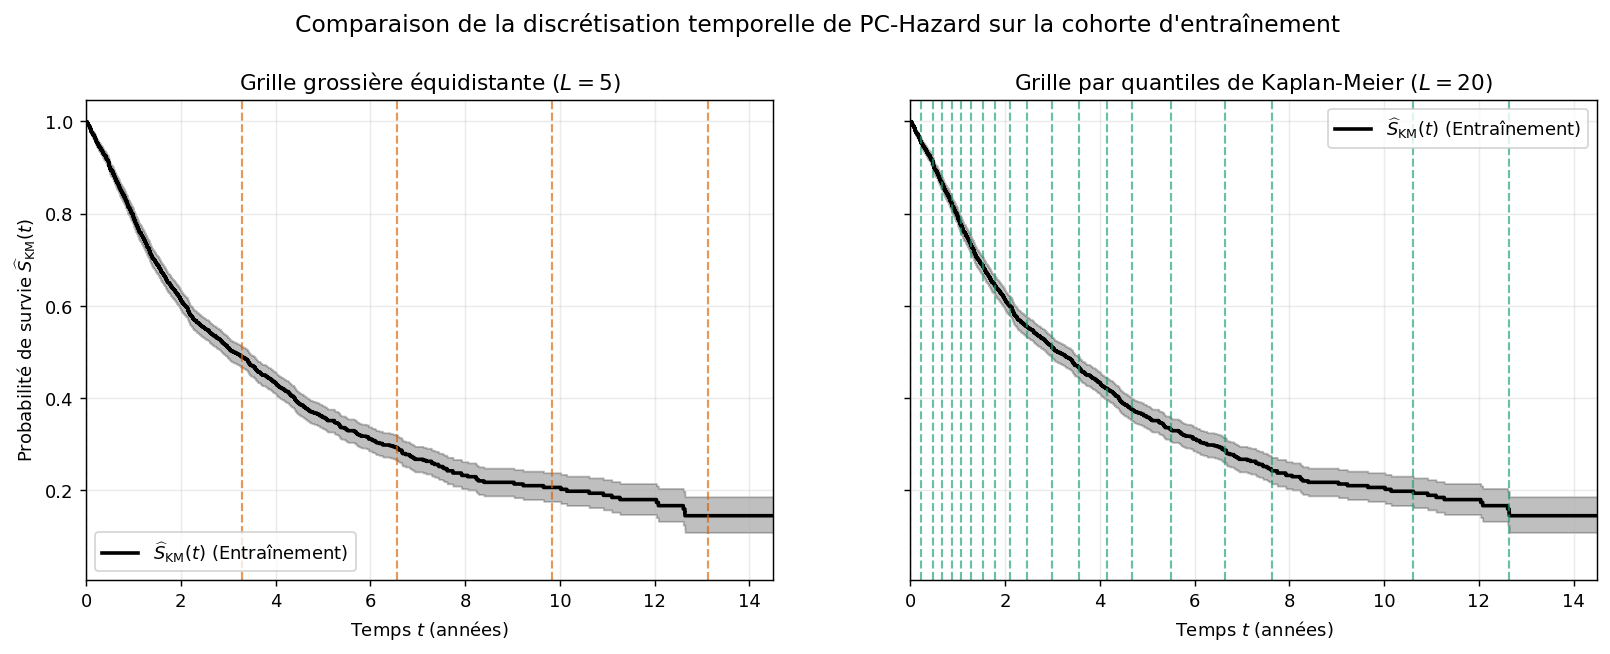

In [25]:
def make_equidistant_grid(times_train, L=5):
    # Grille équidistante grossière sur [0, tau_max].
    tau_max = float(np.max(times_train)) * 1.001
    return np.linspace(0.0, tau_max, L + 1)

def make_kaplan_meier_grid(times_train, events_train, L=20):
    # Grille fondée sur les quantiles de Kaplan-Meier.
    kmf_g = KaplanMeierFitter()
    kmf_g.fit(durations=times_train, event_observed=events_train)
    t_km = kmf_g.survival_function_.index.values
    s_km = kmf_g.survival_function_.values[:, 0]
    s_min = float(s_km[-1])
    target_s = np.linspace(1.0, s_min, L + 1)
    cuts = np.interp(-target_s, -s_km, t_km)
    cuts[0] = 0.0
    cuts[-1] = float(np.max(times_train)) * 1.001
    for idx in range(1, len(cuts)):
        if cuts[idx] <= cuts[idx - 1]:
            cuts[idx] = cuts[idx - 1] + 1e-3
    return cuts

def encode_pchazard_targets(times, events, cuts):
    # Indice d'intervalle k_i = kappa(Y_i) et fraction parcourue rho(Y_i).
    L = len(cuts) - 1
    t_clipped = np.clip(times, cuts[0] + 1e-6, cuts[-1])
    k_idx = np.clip(np.searchsorted(cuts[1:], t_clipped, side="left"), 0, L - 1)
    tau_left = cuts[k_idx]
    delta_tau = cuts[k_idx + 1] - tau_left
    rho = np.clip((t_clipped - tau_left) / np.maximum(delta_tau, 1e-8), 1e-6, 1.0)
    return k_idx.astype(np.int64), rho.astype(np.float64), events.astype(np.float64)

def _np_softplus(x):
    x_c = np.clip(x, -30.0, 30.0)
    return np.log1p(np.exp(-np.abs(x_c))) + np.maximum(x_c, 0.0) + 1e-7

def _np_sigmoid(x):
    return 1.0 / (1.0 + np.exp(-np.clip(x, -30.0, 30.0)))

def _np_pchazard_loss_and_grad(logits, k_idx, rho, events):
    # Perte exacte de PC-Hazard et son gradient.
    n, L = logits.shape
    eta_tilde = _np_softplus(logits)
    arange_L = np.arange(L)[None, :]
    k_col = k_idx[:, None]
    mask_prev = (arange_L < k_col).astype(np.float64)
    mask_curr = (arange_L == k_col).astype(np.float64)
    eta_ki = eta_tilde[np.arange(n), k_idx]
    sum_prev = np.sum(eta_tilde * mask_prev, axis=1)
    loss = float(np.mean(-events * np.log(eta_ki) + sum_prev + rho * eta_ki))
    dL_deta = mask_prev + mask_curr * (rho[:, None] - (events / eta_ki)[:, None])
    dlogits = (dL_deta * _np_sigmoid(logits)) / n
    return loss, dlogits

def train_pchazard_any(X_tr_np, t_tr_np, e_tr_np, cuts, X_va_np=None, t_va_np=None, e_va_np=None,
                       hidden_dims=(64, 32), dropout=0.25, lr=1e-3, weight_decay=2e-3, max_epochs=200, patience=20):
    net = NumpyMLP(X_tr_np.shape[1], hidden_dims, len(cuts) - 1, dropout=dropout, seed=42)
    net.b[-1][:] = -1.5
    k_tr, rho_tr, ev_tr = encode_pchazard_targets(t_tr_np, e_tr_np, cuts)
    if X_va_np is not None:
        k_va, rho_va, ev_va = encode_pchazard_targets(t_va_np, e_va_np, cuts)
    rng = np.random.RandomState(42)
    best_val_loss, best_epoch, best_state, wait = float("inf"), max_epochs, None, 0
    for ep in range(1, max_epochs + 1):
        perm = rng.permutation(len(X_tr_np))
        for b_start in range(0, len(X_tr_np), 256):
            idx_b = perm[b_start:b_start + 256]
            logits_b = net.forward(X_tr_np[idx_b], training=True)
            _, dlogits_b = _np_pchazard_loss_and_grad(logits_b, k_tr[idx_b], rho_tr[idx_b], ev_tr[idx_b])
            net.backward_and_step(dlogits_b, lr=lr, weight_decay=weight_decay)
        if X_va_np is not None:
            val_loss, _ = _np_pchazard_loss_and_grad(net.forward(X_va_np, training=False), k_va, rho_va, ev_va)
            if val_loss < best_val_loss - 1e-4:
                best_val_loss, best_epoch, best_state, wait = val_loss, ep, net.get_state(), 0
            else:
                wait += 1
                if wait >= patience:
                    break
    if best_state is not None:
        net.set_state(best_state)
    return net, best_epoch

def predict_pchazard_any(net, X_np, cuts, eval_times):
    eta_tilde = _np_softplus(net.forward(X_np, training=False))
    L = len(cuts) - 1
    n_samples = X_np.shape[0]
    surv_mat = np.zeros((n_samples, len(eval_times)), dtype=float)
    cum_eta = np.hstack([np.zeros((n_samples, 1)), np.cumsum(eta_tilde, axis=1)])
    for j, t_val in enumerate(eval_times):
        t_c = np.clip(t_val, cuts[0], cuts[-1])
        k_t = min(max(int(np.searchsorted(cuts[1:], t_c, side="left")), 0), L - 1)
        rho_t = min(max((t_c - cuts[k_t]) / max(cuts[k_t + 1] - cuts[k_t], 1e-8), 0.0), 1.0)
        surv_mat[:, j] = np.exp(-(cum_eta[:, k_t] + rho_t * eta_tilde[:, k_t]))
    mask_tau = eval_times <= TAU_QRT
    risk_scores = -np.trapz(surv_mat[:, mask_tau], eval_times[mask_tau], axis=1)
    return surv_mat, risk_scores

L_COARSE = 5
L_KM = 20

# Validation croisée 5-Fold pour PC-Hazard (Grille grossière L=5)
fold_metrics_coarse, ep_list_coarse = [], []
for f in cv_folds:
    cuts_f = make_equidistant_grid(f["df_tr"]["OS_YEARS"].values, L=L_COARSE)
    m_f, ep_f = train_pchazard_any(
        f["X_tr_std"].values, f["df_tr"]["OS_YEARS"].values, f["df_tr"]["OS_STATUS"].values, cuts_f,
        f["X_va_std"].values, f["df_va"]["OS_YEARS"].values, f["df_va"]["OS_STATUS"].values, max_epochs=220, patience=20
    )
    ep_list_coarse.append(ep_f)
    s_va, r_va = predict_pchazard_any(m_f, f["X_va_eval_std"].values, cuts_f, f["ibs_times"])
    fold_metrics_coarse.append(eval_fold_metrics(f["y_tr_surv"], f["y_va_eval_surv"], r_va, s_va, f["ibs_times"]))

arr_c = np.array(fold_metrics_coarse)
cv_pch_coarse = {
    "har_mean": arr_c[:, 0].mean(), "har_std": arr_c[:, 0].std(),
    "uno_mean": arr_c[:, 1].mean(), "uno_std": arr_c[:, 1].std(),
    "ibs_mean": arr_c[:, 2].mean(), "ibs_std": arr_c[:, 2].std(),
}
ep_coarse = max(10, int(np.round(np.mean(ep_list_coarse))))
cuts_train_coarse = make_equidistant_grid(df_train["OS_YEARS"].values, L=L_COARSE)
pch_coarse_final, _ = train_pchazard_any(
    X_train_std.values, df_train["OS_YEARS"].values, df_train["OS_STATUS"].values, cuts_train_coarse, max_epochs=ep_coarse
)
surv_pch_coarse, risk_pch_coarse = predict_pchazard_any(pch_coarse_final, X_test_std.values, cuts_train_coarse, IBS_TIMES)
res_pch_coarse = evaluate_survival_model("PC-Hazard (Grille grossière L=5)", "Grille temporelle", risk_pch_coarse, surv_pch_coarse, cv_stats=cv_pch_coarse)

# Validation croisée 5-Fold pour PC-Hazard (Grille Kaplan-Meier L=20)
fold_metrics_km, ep_list_km = [], []
for f in cv_folds:
    cuts_f = make_kaplan_meier_grid(f["df_tr"]["OS_YEARS"].values, f["df_tr"]["OS_STATUS"].values, L=L_KM)
    m_f, ep_f = train_pchazard_any(
        f["X_tr_std"].values, f["df_tr"]["OS_YEARS"].values, f["df_tr"]["OS_STATUS"].values, cuts_f,
        f["X_va_std"].values, f["df_va"]["OS_YEARS"].values, f["df_va"]["OS_STATUS"].values, max_epochs=220, patience=20
    )
    ep_list_km.append(ep_f)
    s_va, r_va = predict_pchazard_any(m_f, f["X_va_eval_std"].values, cuts_f, f["ibs_times"])
    fold_metrics_km.append(eval_fold_metrics(f["y_tr_surv"], f["y_va_eval_surv"], r_va, s_va, f["ibs_times"]))

arr_k = np.array(fold_metrics_km)
cv_pch_km = {
    "har_mean": arr_k[:, 0].mean(), "har_std": arr_k[:, 0].std(),
    "uno_mean": arr_k[:, 1].mean(), "uno_std": arr_k[:, 1].std(),
    "ibs_mean": arr_k[:, 2].mean(), "ibs_std": arr_k[:, 2].std(),
}
ep_km = max(10, int(np.round(np.mean(ep_list_km))))
cuts_train_km = make_kaplan_meier_grid(df_train["OS_YEARS"].values, df_train["OS_STATUS"].values, L=L_KM)
pch_km_final, _ = train_pchazard_any(
    X_train_std.values, df_train["OS_YEARS"].values, df_train["OS_STATUS"].values, cuts_train_km, max_epochs=ep_km
)
surv_pch_km, risk_pch_km = predict_pchazard_any(pch_km_final, X_test_std.values, cuts_train_km, IBS_TIMES)
res_pch_km = evaluate_survival_model("PC-Hazard (Grille Kaplan-Meier L=20)", "Grille temporelle", risk_pch_km, surv_pch_km, cv_stats=cv_pch_km)

print(f"=== PC-Hazard — Grille grossière équidistante (L={L_COARSE}, epochs_cv_mean={ep_coarse}) ===")
print(f"CV 5-Fold Harrell          : {cv_pch_coarse['har_mean']:.4f} ± {cv_pch_coarse['har_std']:.4f}")
print(f"CV 5-Fold Uno (tau=7ans)   : {cv_pch_coarse['uno_mean']:.4f} ± {cv_pch_coarse['uno_std']:.4f}")
print(f"CV 5-Fold IBS              : {cv_pch_coarse['ibs_mean']:.4f} ± {cv_pch_coarse['ibs_std']:.4f}")
print(f"Test Externe Harrell       : {res_pch_coarse['C-index Harrell']:.4f}")
print(f"Test Externe Uno           : {res_pch_coarse['C-index Uno (IPCW)']:.4f}")
print(f"Test Externe IBS           : {res_pch_coarse['IBS']:.4f}\n")

print(f"=== PC-Hazard — Grille de Kaplan-Meier (L={L_KM}, epochs_cv_mean={ep_km}) ===")
print(f"CV 5-Fold Harrell          : {cv_pch_km['har_mean']:.4f} ± {cv_pch_km['har_std']:.4f}")
print(f"CV 5-Fold Uno (tau=7ans)   : {cv_pch_km['uno_mean']:.4f} ± {cv_pch_km['uno_std']:.4f}")
print(f"CV 5-Fold IBS              : {cv_pch_km['ibs_mean']:.4f} ± {cv_pch_km['ibs_std']:.4f}")
print(f"Test Externe Harrell       : {res_pch_km['C-index Harrell']:.4f}")
print(f"Test Externe Uno           : {res_pch_km['C-index Uno (IPCW)']:.4f}")
print(f"Test Externe IBS           : {res_pch_km['IBS']:.4f}")

fig_grids, axes_g = plt.subplots(1, 2, figsize=(15, 4.8), sharey=True)
kmf_tr = KaplanMeierFitter()
kmf_tr.fit(df_train["OS_YEARS"], df_train["OS_STATUS"], label=r"$\widehat{S}_{\mathrm{KM}}(t)$ (Entraînement)")

for ax, cuts_g, title_g, col_g in [
    (axes_g[0], cuts_train_coarse, f"Grille grossière équidistante ($L={L_COARSE}$)", "#D95F02"),
    (axes_g[1], cuts_train_km, f"Grille par quantiles de Kaplan-Meier ($L={L_KM}$)", "#1B9E77"),
]:
    kmf_tr.plot_survival_function(ax=ax, ci_show=True, color="black", lw=2)
    for c_val in cuts_g:
        ax.axvline(c_val, color=col_g, ls="--", alpha=0.65, lw=1.2)
    ax.set_title(title_g)
    ax.set_xlabel("Temps $t$ (années)")
    ax.set_ylabel(r"Probabilité de survie $\widehat{S}_{\mathrm{KM}}(t)$")
    ax.set_xlim(0, min(14.5, float(df_train["OS_YEARS"].max())))
    ax.grid(alpha=0.25)

fig_grids.suptitle("Comparaison de la discrétisation temporelle de PC-Hazard sur la cohorte d'entraînement", fontsize=13, y=1.02)
plt.show()

### 6. Bilan des résultats : Validation Croisée 5-Fold et Benchmark sur le Test externe

Les deux tableaux et les graphiques ci-dessous présentent :
1. la **robustesse en validation croisée 5-fold** (moyenne $\pm$ écart-type sur les 5 plis d'entraînement),
2. la **performance finale hors-échantillon** sur l'ensemble de test externe gelé, comparée au **Modèle de Cox de référence**.

=== Tableau 1 : Validation Croisée 5-Fold sur Train (n=2538, Moyenne ± Écart-type inter-plis) ===
                              Modèle CV Harrell (Moy ± Std) CV Uno (Moy ± Std) CV IBS (Moy ± Std)
                     Cox (Référence)        0.7252 ± 0.0119    0.7021 ± 0.0170    0.1677 ± 0.0056
     Arbre de Survie (CART Log-Rank)        0.6895 ± 0.0147    0.6701 ± 0.0188    0.1838 ± 0.0084
              Random Survival Forest        0.7388 ± 0.0131    0.7146 ± 0.0163    0.1646 ± 0.0065
            Gradient Boosting de Cox        0.7383 ± 0.0111    0.7154 ± 0.0142    0.1634 ± 0.0058
                            DeepSurv        0.7231 ± 0.0162    0.7002 ± 0.0205    0.1690 ± 0.0068
    PC-Hazard (Grille grossière L=5)        0.7197 ± 0.0161    0.6949 ± 0.0216    0.1720 ± 0.0066
PC-Hazard (Grille Kaplan-Meier L=20)        0.7254 ± 0.0121    0.7000 ± 0.0190    0.1688 ± 0.0067

=== Tableau 2 : Synthèse comparative finale sur l'ensemble de Test Externe (n=631, Benchmark sur Cox) ===
           

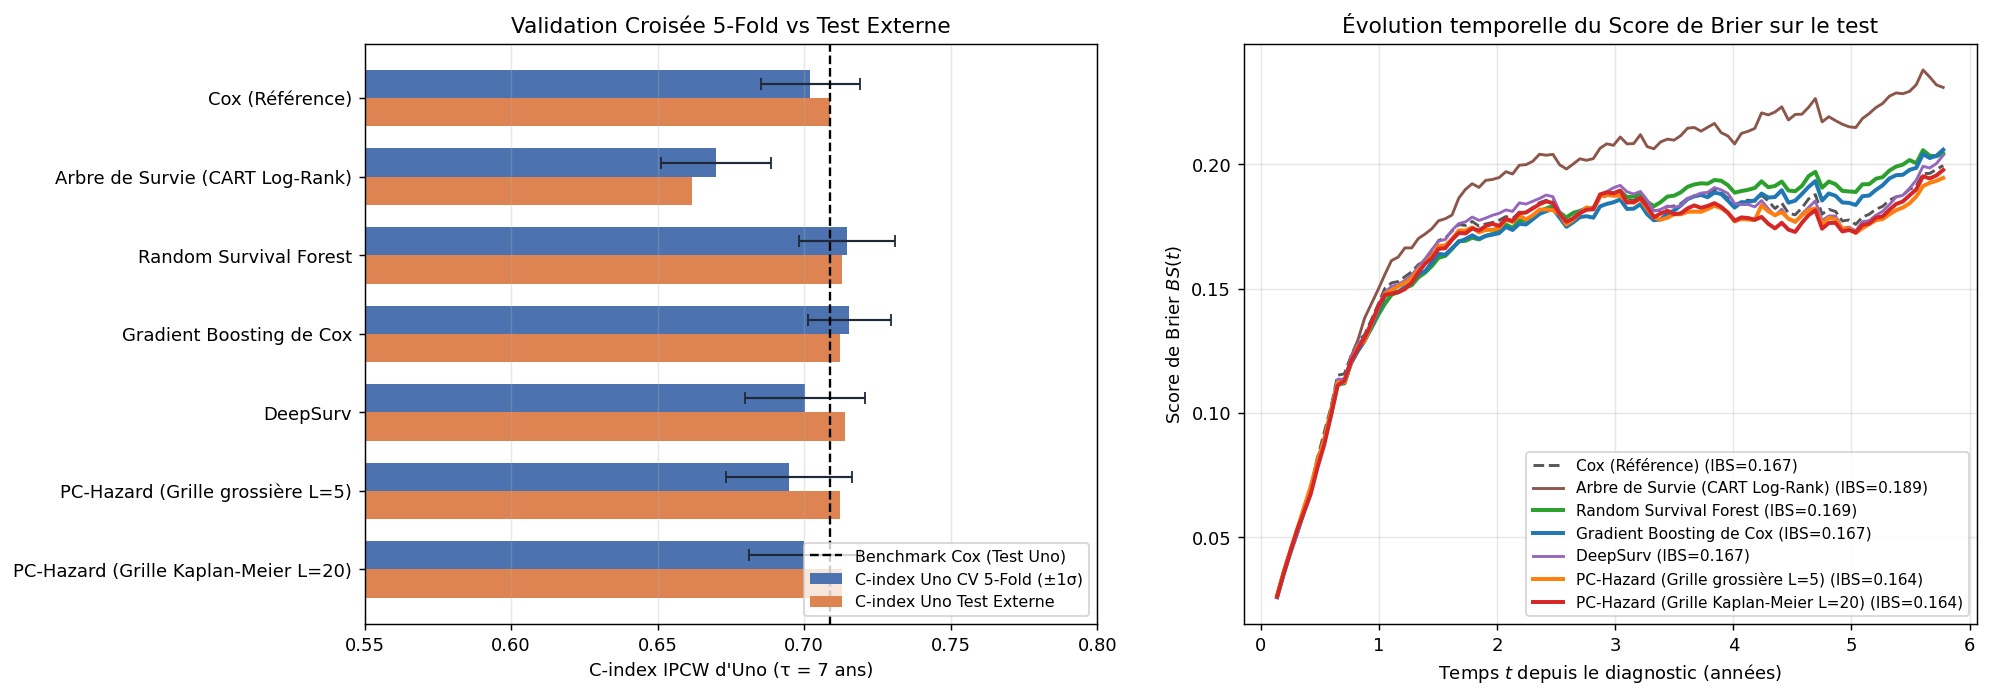

In [26]:
all_results = [
    res_cox,
    res_tree,
    res_rsf,
    res_gbm,
    res_deepsurv,
    res_pch_coarse,
    res_pch_km,
]

df_cv_summary = pd.DataFrame([
    {
        "Modèle": r["Modèle"],
        "CV Harrell (Moy ± Std)": f"{r['CV Harrell Mean']:.4f} ± {r['CV Harrell Std']:.4f}",
        "CV Uno (Moy ± Std)": f"{r['CV Uno Mean']:.4f} ± {r['CV Uno Std']:.4f}",
        "CV IBS (Moy ± Std)": f"{r['CV IBS Mean']:.4f} ± {r['CV IBS Std']:.4f}",
    }
    for r in all_results
])

df_bench = pd.DataFrame([
    {
        "Modèle": r["Modèle"],
        "Catégorie": r["Catégorie"],
        "CV Uno (Moy)": r["CV Uno Mean"],
        "CV Uno (Std)": r["CV Uno Std"],
        "Test Harrell": r["C-index Harrell"],
        "Test Uno (tau=7)": r["C-index Uno (IPCW)"],
        "Gain Uno vs Cox": r["C-index Uno (IPCW)"] - res_cox["C-index Uno (IPCW)"],
        "Test IBS": r["IBS"],
    }
    for r in all_results
])

print("=== Tableau 1 : Validation Croisée 5-Fold sur Train (n=2538, Moyenne ± Écart-type inter-plis) ===")
print(df_cv_summary.to_string(index=False))

print("\n=== Tableau 2 : Synthèse comparative finale sur l'ensemble de Test Externe (n=631, Benchmark sur Cox) ===")
print(df_bench[["Modèle", "Catégorie", "Test Harrell", "Test Uno (tau=7)", "Gain Uno vs Cox", "Test IBS"]].to_string(index=False, float_format=lambda x: f"{x:.4f}"))

fig_bench, axes_b = plt.subplots(1, 2, figsize=(16, 5.8))

y_pos = np.arange(len(df_bench))
h_bar = 0.36
axes_b[0].barh(
    y_pos - h_bar/2, df_bench["CV Uno (Moy)"], xerr=df_bench["CV Uno (Std)"],
    height=h_bar, label="C-index Uno CV 5-Fold (±1σ)", color="#4C72B0", capsize=3.5, error_kw={"ecolor": "#1f2937", "lw": 1.2}
)
axes_b[0].barh(
    y_pos + h_bar/2, df_bench["Test Uno (tau=7)"],
    height=h_bar, label="C-index Uno Test Externe", color="#DD8452"
)
axes_b[0].axvline(res_cox["C-index Uno (IPCW)"], color="black", ls="--", lw=1.3, label="Benchmark Cox (Test Uno)")
axes_b[0].set_yticks(y_pos)
axes_b[0].set_yticklabels(df_bench["Modèle"])
axes_b[0].invert_yaxis()
axes_b[0].set_xlim(0.55, max(0.80, df_bench["Test Uno (tau=7)"].max() + 0.04))
axes_b[0].set_xlabel("C-index IPCW d'Uno (τ = 7 ans)")
axes_b[0].set_title("Validation Croisée 5-Fold vs Test Externe")
axes_b[0].legend(loc="lower right", fontsize=8.8)
axes_b[0].grid(axis="x", alpha=0.3)

palette = ["#555555", "#8C564B", "#2CA02C", "#1F77B4", "#9467BD", "#FF7F0E", "#D62728"]
for r, col in zip(all_results, palette):
    ls = "--" if "Cox (Référence)" in r["Modèle"] else "-"
    lw = 2.2 if "PC-Hazard" in r["Modèle"] or "Boosting" in r["Modèle"] or "Forest" in r["Modèle"] else 1.6
    axes_b[1].plot(IBS_TIMES, r["bs_curve"], label=f"{r['Modèle']} (IBS={r['IBS']:.3f})", color=col, ls=ls, lw=lw)

axes_b[1].set_xlabel("Temps $t$ depuis le diagnostic (années)")
axes_b[1].set_ylabel(r"Score de Brier $BS(t)$")
axes_b[1].set_title("Évolution temporelle du Score de Brier sur le test")
axes_b[1].legend(fontsize=8.5, loc="lower right")
axes_b[1].grid(alpha=0.3)
plt.show()

### 7. Calibration des fonctions de survie à horizon fixé $t^\star$

La calibration examine l'accord entre les probabilités de survie prédites et les fréquences de survie réellement observées à l'horizon médian des événements d'entraînement :

$$t^\star = \min\left\lbrace t_{\max},\ \max\left\lbrace t_{\min},\ \mathrm{med}\lbrace Y_i : \Delta_i = 1,\ i \in \mathcal D_{\mathrm{train}}\rbrace \right\rbrace \right\rbrace$$

Pour chaque modèle et chaque individu $i$ de l'ensemble de test évalué :
1. On extrait la probabilité de survie prédite $\hat p_i = \widehat{S}(t^\star \mid X_i)$.
2. On ordonne et découpe les probabilités $\hat p_i$ en 5 groupes $G_1, \dots, G_5$ selon leurs quintiles empiriques (`pd.qcut`).
3. Dans chaque groupe $G_k$ ($k=1,\dots,5$), on compare la **survie moyenne prédite** :

$$\hat p_k = \frac{1}{|G_k|} \sum_{i \in G_k} \widehat{S}(t^\star \mid X_i)$$

à la **survie observée estimée séparément par Kaplan–Meier** dans ce groupe :

$$\hat o_k = \hat S_{\mathrm{KM}, k}(t^\star) = \prod_{u \le t^\star} \left(1 - \frac{d_k(u)}{n_k(u)}\right)$$

Un point $(\hat p_k, \hat o_k)$ situé sur la première bissectrice $y = x$ correspond à une calibration parfaite ; lorsque $\hat o_k > \hat p_k$, le modèle sous-estime la survie (surestime le risque), et inversement lorsque $\hat o_k < \hat p_k$.

Horizon temporel de calibration fixé : t* = 1.38 années

=== Écart absolu moyen de calibration |o_k - p_k| sur les 5 quintiles à t* ===
  - Cox (Référence)                      : MAE calibration = 0.0285
  - Arbre de Survie (CART Log-Rank)      : MAE calibration = 0.0392
  - Random Survival Forest               : MAE calibration = 0.0559
  - Gradient Boosting de Cox             : MAE calibration = 0.0301
  - DeepSurv                             : MAE calibration = 0.0455
  - PC-Hazard (Grille grossière L=5)     : MAE calibration = 0.0229
  - PC-Hazard (Grille Kaplan-Meier L=20) : MAE calibration = 0.0295

Table de calibration pour Cox (Référence) à t* = 1.38 ans :
 Groupe  Effectif  Survie moyenne prédite  Survie observée KM  Écart absolu
      1       127                  0.3528              0.3583        0.0055
      2       126                  0.6465              0.6034        0.0431
      3       126                  0.7730              0.7558        0.0172
      4       126      

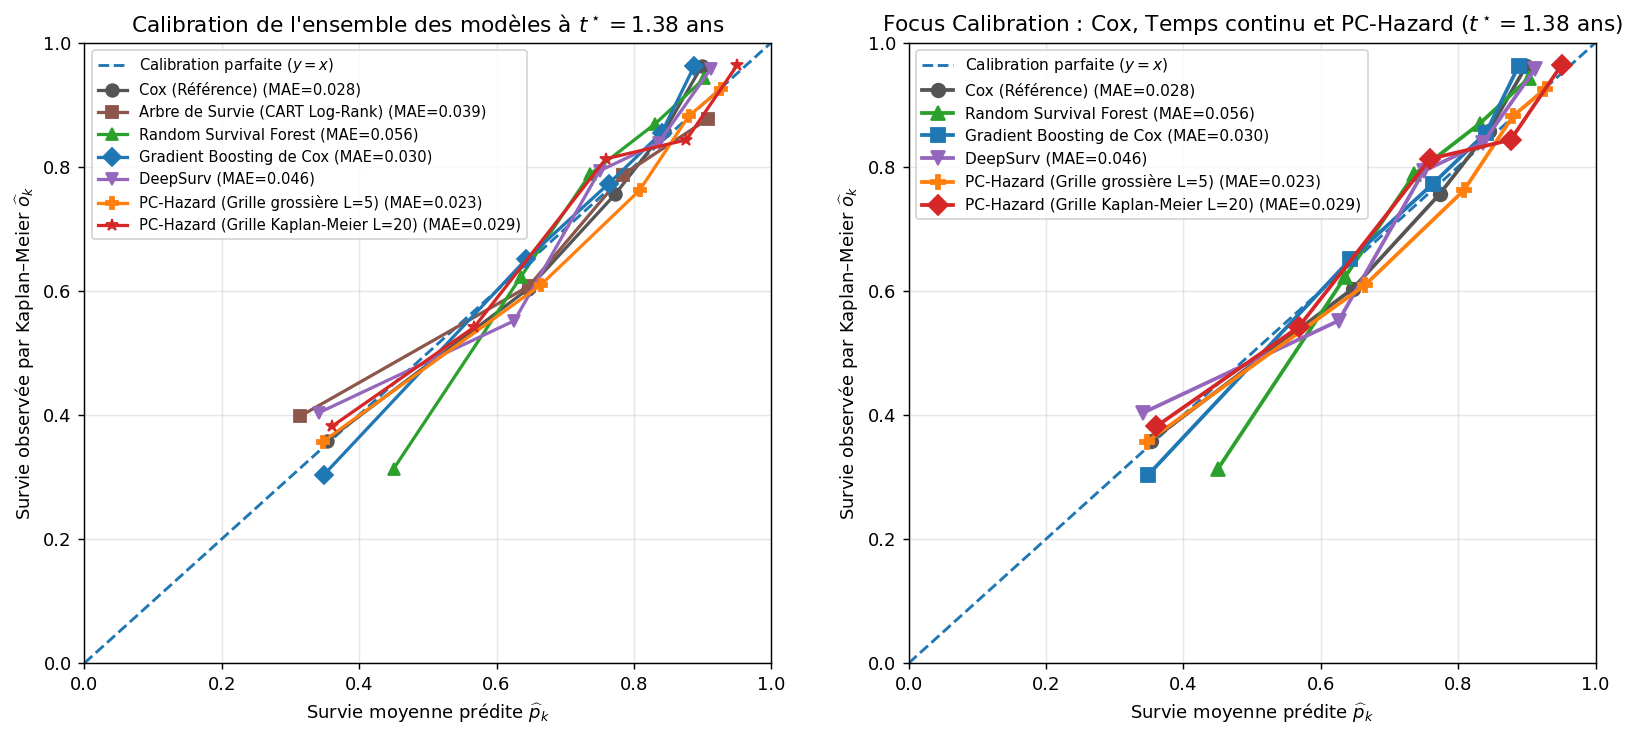

In [27]:
med_event_train = float(np.median(df_train.loc[df_train["OS_STATUS"] == 1, "OS_YEARS"]))
t_star = min(t_max_ibs, max(t_min_ibs, med_event_train))
print(f"Horizon temporel de calibration fixé : t* = {t_star:.2f} années")

def compute_calibration_curve_km(surv_matrix, times_grid, t_horizon, df_eval_test, n_groups=5):
    p_hat = np.array([np.interp(t_horizon, times_grid, row) for row in surv_matrix])
    groups = pd.qcut(p_hat, q=n_groups, labels=False, duplicates="drop")
    rows = []
    kmf_c = KaplanMeierFitter()
    for g_id in sorted(np.unique(groups)):
        mask_g = (groups == g_id)
        p_mean = float(np.mean(p_hat[mask_g]))
        sub_df = df_eval_test.iloc[np.where(mask_g)[0]]
        kmf_c.fit(durations=sub_df["OS_YEARS"], event_observed=sub_df["OS_STATUS"])
        t_index = kmf_c.survival_function_.index.values
        s_vals = kmf_c.survival_function_.values[:, 0]
        idx_pos = np.searchsorted(t_index, t_horizon, side="right") - 1
        o_km = float(s_vals[max(idx_pos, 0)]) if idx_pos >= 0 else 1.0
        rows.append({
            "Groupe": int(g_id) + 1,
            "Effectif": int(mask_g.sum()),
            "Survie moyenne prédite": p_mean,
            "Survie observée KM": o_km,
            "Écart absolu": abs(o_km - p_mean),
        })
    return pd.DataFrame(rows)

calib_tables = {}
calib_mae = {}
for r in all_results:
    m_name = r["Modèle"]
    df_c = compute_calibration_curve_km(r["surv_matrix"], IBS_TIMES, t_star, df_test_eval, n_groups=5)
    calib_tables[m_name] = df_c
    calib_mae[m_name] = float(df_c["Écart absolu"].mean())

print("\n=== Écart absolu moyen de calibration |o_k - p_k| sur les 5 quintiles à t* ===")
for m_name, mae_v in calib_mae.items():
    print(f"  - {m_name:<36} : MAE calibration = {mae_v:.4f}")

for target_m in ["Cox (Référence)", "PC-Hazard (Grille grossière L=5)", "PC-Hazard (Grille Kaplan-Meier L=20)"]:
    print(f"\nTable de calibration pour {target_m} à t* = {t_star:.2f} ans :")
    print(calib_tables[target_m][["Groupe", "Effectif", "Survie moyenne prédite", "Survie observée KM", "Écart absolu"]].to_string(index=False, float_format=lambda x: f"{x:.4f}"))

fig_cal, axes_c = plt.subplots(1, 2, figsize=(15, 6.2))
palette = ["#555555", "#8C564B", "#2CA02C", "#1F77B4", "#9467BD", "#FF7F0E", "#D62728"]

axes_c[0].plot([0, 1], [0, 1], "--", color="#1F77B4", lw=1.6, label="Calibration parfaite ($y = x$)")
markers = ["o", "s", "^", "D", "v", "P", "*"]
for r, col, mk in zip(all_results, palette, markers):
    m_name = r["Modèle"]
    dfc = calib_tables[m_name]
    axes_c[0].plot(
        dfc["Survie moyenne prédite"], dfc["Survie observée KM"],
        marker=mk, markersize=7, lw=1.8, color=col,
        label=f"{m_name} (MAE={calib_mae[m_name]:.3f})",
    )
axes_c[0].set_xlim(0.0, 1.0)
axes_c[0].set_ylim(0.0, 1.0)
axes_c[0].set_xlabel(r"Survie moyenne prédite $\widehat{p}_k$")
axes_c[0].set_ylabel(r"Survie observée par Kaplan–Meier $\widehat{o}_k$")
axes_c[0].set_title(f"Calibration de l'ensemble des modèles à $t^\\star = {t_star:.2f}$ ans")
axes_c[0].legend(fontsize=8.2, loc="upper left")
axes_c[0].grid(alpha=0.3)

axes_c[1].plot([0, 1], [0, 1], "--", color="#1F77B4", lw=1.6, label="Calibration parfaite ($y = x$)")
focus_models = [
    ("Cox (Référence)", "#555555", "o"),
    ("Random Survival Forest", "#2CA02C", "^"),
    ("Gradient Boosting de Cox", "#1F77B4", "s"),
    ("DeepSurv", "#9467BD", "v"),
    ("PC-Hazard (Grille grossière L=5)", "#FF7F0E", "P"),
    ("PC-Hazard (Grille Kaplan-Meier L=20)", "#D62728", "D"),
]
for m_name, col, mk in focus_models:
    dfc = calib_tables[m_name]
    axes_c[1].plot(
        dfc["Survie moyenne prédite"], dfc["Survie observée KM"],
        marker=mk, markersize=7.5, lw=2.1, color=col,
        label=f"{m_name} (MAE={calib_mae[m_name]:.3f})",
    )
axes_c[1].set_xlim(0.0, 1.0)
axes_c[1].set_ylim(0.0, 1.0)
axes_c[1].set_xlabel(r"Survie moyenne prédite $\widehat{p}_k$")
axes_c[1].set_ylabel(r"Survie observée par Kaplan–Meier $\widehat{o}_k$")
axes_c[1].set_title(f"Focus Calibration : Cox, Temps continu et PC-Hazard ($t^\\star = {t_star:.2f}$ ans)")
axes_c[1].legend(fontsize=8.5, loc="upper left")
axes_c[1].grid(alpha=0.3)
plt.show()

### Interprétation des résultats et de la figure de calibration

1. **Test de Schoenfeld et limites du modèle de Cox linéaire** :
   - Le test des résidus de Schoenfeld rejette l'hypothèse des risques proportionnels au seuil de $5\%$ pour **7 covariables sur 73** (notamment `MUT_NPM1` avec $p < 10^{-4}$, `PLT`, `MUT_U2AF1`, `MUT_TP53`, `MUT_WT1`, `MUT_SF3B1` et `MUT_KMT2D`), confirmant une variation temporelle marquée des rapports de risques au cours du suivi.
   - Le modèle de Cox pénalisé par validation croisée (`penalizer=0.1`) atteint un **C-index IPCW de Uno de `0.7021 ± 0.0170` en CV 5-fold** et **`0.7089` sur le Test externe** ($\mathrm{IBS} = 0.1670$).

2. **Robustesse en Validation Croisée 5-Fold et Apport des méthodes d'apprentissage non linéaires** :
   - En **validation croisée 5-fold**, le **Gradient Boosting de Cox** (`0.7154 ± 0.0142` en Uno IPCW, `0.1634 ± 0.0058` en IBS) et le **Random Survival Forest** (`0.7146 ± 0.0163` en Uno IPCW, `0.7388 ± 0.0131` en Harrell) obtiennent les meilleures moyennes inter-plis tout en réduisant l'écart-type par rapport aux modèles individuels.
   - Sur le **Test externe**, **DeepSurv** (`0.7140` en Uno IPCW), **Random Survival Forest** (`0.7366` en Harrell, `0.7130` en Uno), **Gradient Boosting** (`0.7363` en Harrell, `0.7123` en Uno) et **PC-Hazard (KM)** (`0.7356` en Harrell, `0.7129` en Uno) surpassent tous le benchmark de Cox et améliorent fortement la précision probabiliste globale (**$\mathrm{IBS} = 0.1640$** pour PC-Hazard).

3. **Effet du maillage temporel de PC-Hazard (Grille grossière vs Kaplan–Meier)** :
   - En validation croisée 5-fold, la **grille de Kaplan–Meier ($L=20$)** domine nettement la **grille équidistante grossière ($L=5$)** sur toutes les métriques (**CV Harrell : `0.7254 ± 0.0121` vs `0.7197 ± 0.0161` ; CV Uno : `0.7000 ± 0.0190` vs `0.6949 ± 0.0216` ; CV IBS : `0.1688 ± 0.0067` vs `0.1720 ± 0.0066`**). Concentrer les intervalles dans les premières années où se produisent les décès réduit à la fois le biais de discrétisation et la variance inter-plis.

4. **Lecture de la figure de calibration à $t^\star = 1.38\text{ an}$** :
   - Les deux modèles **PC-Hazard** affichent les plus faibles écarts absolus moyens de calibration ($|\hat o_k - \hat p_k|$ de **`0.0229`** pour la grille grossière et **`0.0295`** pour la grille KM) et suivent fidèlement la bissectrice $y = x$ sur les 5 quintiles de risque (de $\hat p_1 \approx 0.36$ jusqu'à $\hat p_5 \approx 0.95$), devant le **Random Survival Forest** (`0.0559`) et **DeepSurv** (`0.0455`).